# Baseline candidates: calibration, dipoles and TEPs per baseline window

This notebook runs the online calibration of one session once per candidate TEP baseline window and compares
what each window changes: the calibration outcomes, the dipole, and the sensor-space TEPs of the calibration
block and of the open-loop blocks. The online code in `prime/decider/prime_core` is imported read-only. The
baseline is set on the notebook's own `Preprocessor` objects; no file in `prime/` is modified.

- **candidates**: every window in `CANDIDATES`, all on the same [−200, 100] ms buffer, so they differ only in
  the baseline. [−25, −15] ms is the online baseline on this longer buffer.
- **online**: the stored online calibration (bundle and dipole) on the online [−30, 100] ms buffer, as the
  reference.

Only the post-stimulus side of the calibration is replayed: `Preprocessor.calibrate()` →
`DipoleFitter.calibrate()` → `TEPNormalizer.calibrate()`. The model (`OnlinePredictor`) is left out, so the
notebook needs no GPU and gives the same result on every machine.

| section | content |
|---|---|
| 0 | parameters |
| 1 | setup, completeness check |
| 2 | stitched [−200, 100] ms raw buffers for every trial |
| 3 | calibration per candidate; calibration and open-loop epochs |
| 4 | calibration outcomes across candidates |
| 5 | dipoles per candidate |
| 6 | dipole plots: positions, time windows |
| 7 | dipoles compared with the online dipole; bootstrap stability |
| 8 | sensor-space TEPs: calibration block, baseline + evaluation blocks |

**Requirements.** `mne`, `mne-icalabel`, `omegaconf` (as the decider). A few minutes per session.

## 0 · Parameters

All paths follow from `SUBJECT_ID`. `RUN_ID = None` picks the run folder that holds
`prime/trials_intervention.csv`. Output folders are created when missing.

In [43]:
# ---------------------------------------------------------------- session
SUBJECT_ID = "pilot003"          # BIDS subject label, without "sub-"
SESSION_ID = "ses-prime"
RUN_ID     = None                # NeuroSimo run folder, e.g. "105"; None = the one folder with prime/trials_intervention.csv

# ---------------------------------------------------------------- candidate baseline windows (s)
CANDIDATES = [
    #(-0.200, -0.066),
    #(-0.165, -0.066),
    #(-0.075, -0.066),
    (-0.025, -0.015),            # the online baseline, here on the long buffer
]
RAW_WINDOW = (-0.200, 0.100)     # s, raw buffer every candidate is processed on; must contain every window

# ---------------------------------------------------------------- outputs
OUT_DIR       = None             # None: <Loop>/offline_baseline/sub-<ID>/baseline_candidates
NEW_RAW_DIR   = None             # None: BIDS/sub-<ID>/<SESSION>/<RUN>/new_raw_trial
OVERWRITE_RAW = False            # rewrite stitched buffers that already exist
SAVE_FIGURES  = True             # PNGs in OUT_DIR/figures

# ---------------------------------------------------------------- TEP plots
ROI_CHANNELS   = ["C1", "C3", "FC1", "FC3", "CP1", "CP3"]      # left M1
SINGLE_CHANNEL = "Cz"
TOPO_WINDOW    = (0.038, 0.050)  # s, fixed topoplot window (the dipole search window)

# ---------------------------------------------------------------- dipole bootstrap
N_BOOT    = 200                  # resamples of the calibration trials per source; 0 skips the bootstrap
BOOT_SEED = 0

# ---------------------------------------------------------------- decider settings that changed between sessions
SESSION_OVERRIDES = {
    "pilot003": {"ocular_z_threshold": 2.0},   # ran before commit f4fd395 (2026-09-17: 2.0 -> 2.5)
    "pilot004": {"ocular_z_threshold": 2.0},
}

## 1 · Setup and completeness check

### 1.1 Setup

`prime/decider` goes on `sys.path` with `sys.dont_write_bytecode = True`, so nothing is written into `prime/`.
In memory only: `np.trapz` → `np.trapezoid` where NumPy ≥ 2.4 removed it (the bad-channel check still calls
it), and `SESSION_OVERRIDES`.

Every candidate has to lie inside `RAW_WINDOW` and end before the artifact window (−14 ms). It may start on the
buffer's first sample: `preprocess_post()` resamples 5 kHz → 1 kHz with reflection padding, which changes only
the first resampled sample. On pilot005's calibration trials that moved the [−200, −66] ms baseline mean by at
most 0.13 µV (median 0.003 µV).

In [44]:
import contextlib, io, json, os, platform, sys, textwrap, time, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 200)

if not hasattr(np, "trapz"):     # NumPy >= 2.4 removed np.trapz; Preprocessor.calibrate() still calls it
    np.trapz = np.trapezoid      # (bad-channel AUC). Same function, new name; in memory only.


def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError("Loop root not found; set the LOOP_ROOT environment variable.")


# ---------------------------------------------------------------- paths, all derived from SUBJECT_ID
LOOP_ROOT    = _find_loop_root()
PRIME_DIR    = LOOP_ROOT / "prime"
DECIDER_DIR  = PRIME_DIR / "decider"
FORWARD_PATH = PRIME_DIR / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
SESSION_DIR  = LOOP_ROOT / "BIDS" / f"sub-{SUBJECT_ID}" / SESSION_ID
if RUN_ID is None:
    runs = sorted({p.parent.parent.name for p in SESSION_DIR.glob("*/prime/trials_intervention.csv")})
    if len(runs) != 1:
        raise FileNotFoundError(f"expected one run folder with prime/trials_intervention.csv in {SESSION_DIR}, "
                                f"found {runs}; set RUN_ID")
    RUN_ID = runs[0]
ONLINE_DIR  = SESSION_DIR / RUN_ID / "prime"               # everything the online decider wrote
NEW_RAW_DIR = Path(NEW_RAW_DIR) if NEW_RAW_DIR else SESSION_DIR / RUN_ID / "new_raw_trial"
OUT_DIR     = Path(OUT_DIR) if OUT_DIR else LOOP_ROOT / "offline_baseline" / f"sub-{SUBJECT_ID}" / "baseline_candidates"
FIG_DIR     = OUT_DIR / "figures"
for p in (ONLINE_DIR, DECIDER_DIR, FORWARD_PATH):
    if not p.exists():
        raise FileNotFoundError(p)
for p in (NEW_RAW_DIR, OUT_DIR):                           # outputs never go into prime/ or the online folder
    if p.resolve().is_relative_to(PRIME_DIR.resolve()) or p.resolve().is_relative_to(ONLINE_DIR.resolve()):
        raise ValueError(f"output folder inside prime/ or the online folder: {p}")
OUT_DIR.mkdir(parents=True, exist_ok=True)
if SAVE_FIGURES:
    FIG_DIR.mkdir(exist_ok=True)

# ---------------------------------------------------------------- the online code, read-only
sys.dont_write_bytecode = True                             # no __pycache__ written into prime/
if str(DECIDER_DIR) not in sys.path:
    sys.path.insert(0, str(DECIDER_DIR))
import mne
try:
    import mne_icalabel
except ImportError as err:
    raise ImportError("the calibration needs mne-icalabel: pip install mne-icalabel") from err
from prime_core.tep_normalizer import TEPNormalizer
from prime_core.preprocessing.preprocessor import (
    Preprocessor, _butter_filter, _interpolate_bad_channels, _detect_bad_channels_qc, _detect_bad_channels_post,
)
from prime_core.preprocessing.dipole_fitter import (
    DipoleFitter, determine_optimal_index_range, determine_optimal_ori_and_pos,
)
from prime_core.preprocessing.config import get_default_config
from prime_core.prime_config import (
    get_raw_sfreq, get_processed_sfreq, get_calibration_time_range, get_qc_time_range,
    get_post_initial_time_range, get_post_time_range, get_dipole_time_range,
)
mne.set_log_level("ERROR")

# ---------------------------------------------------------------- time windows (configs/prime.yaml)
RAW_SFREQ, PROC_SFREQ    = get_raw_sfreq(), get_processed_sfreq()   # 5000 / 1000 Hz
CAL_TMIN, CAL_TMAX       = get_calibration_time_range()             # _trial_raw.npy [-1100, 100] ms
QC_TMIN, QC_TMAX         = get_qc_time_range()                      # _pre_raw.npy   [-210, -10] ms
POST_I_TMIN, POST_I_TMAX = get_post_initial_time_range()            # _post_raw.npy  [-30, 100] ms
POST_TMIN, POST_TMAX     = get_post_time_range()                    # processed post epoch [1, 100] ms
DIP_TMIN, DIP_TMAX       = get_dipole_time_range()                  # dipole search window [38, 50] ms
DEFAULT_CFG              = get_default_config()
ONLINE_BASELINE          = tuple(DEFAULT_CFG.baseline)              # [-25, -15] ms
ARTIFACT_START           = DEFAULT_CFG.artifact_window_1[0]         # -14 ms
TAPER_END                = DEFAULT_CFG.artifact_window_2[1]         # 15 ms: the processed epoch is tapered up to here
OVERRIDES                = SESSION_OVERRIDES.get(SUBJECT_ID, {})

ms = lambda w: f"[{w[0] * 1e3:.0f}, {w[1] * 1e3:.0f}] ms"
if not (QC_TMIN - 1e-9 <= RAW_WINDOW[0] and np.isclose(RAW_WINDOW[1], POST_I_TMAX)):
    raise ValueError(f"RAW_WINDOW must start at or after {QC_TMIN * 1e3:.0f} ms and end at {POST_I_TMAX * 1e3:.0f} ms")
if len({tuple(b) for b in CANDIDATES}) != len(CANDIDATES):
    raise ValueError("CANDIDATES lists a window twice")
for b in CANDIDATES:
    if not (RAW_WINDOW[0] - 1e-9 <= b[0] < b[1] <= ARTIFACT_START + 1e-9):
        raise ValueError(f"baseline {ms(b)} must lie within {ms((RAW_WINDOW[0], ARTIFACT_START))}")
if not (POST_TMIN <= TOPO_WINDOW[0] < TOPO_WINDOW[1] <= POST_TMAX):
    raise ValueError(f"TOPO_WINDOW must lie within {ms((POST_TMIN, POST_TMAX))}")

# ---------------------------------------------------------------- stitched raw buffers (section 2)
RAW_TAG = f"raw_{RAW_WINDOW[0] * 1e3:.0f}_{RAW_WINDOW[1] * 1e3:.0f}ms"


def new_raw_path(stem):
    return NEW_RAW_DIR / f"{stem}_{RAW_TAG}.npy"


def trial_times(tmin, n):
    # Sample times of a raw buffer starting at tmin. The decider's timestamps were not saved; crop_eeg_buffer()
    # only reads the first one, so a uniform grid reproduces every crop.
    return tmin + np.arange(n) / RAW_SFREQ


def git_head(repo: Path) -> str:
    # Commit of the prime repository, read from .git without running git.
    git = repo / ".git"
    try:
        head = (git / "HEAD").read_text().strip()
        if not head.startswith("ref:"):
            return head
        ref = head.split(maxsplit=1)[1]
        if (git / ref).is_file():
            return (git / ref).read_text().strip()
        for line in (git / "packed-refs").read_text().splitlines():
            if line.endswith(" " + ref):
                return line.split()[0]
    except OSError:
        pass
    try:                                                   # last entry of the reflog
        return (git / "logs" / "HEAD").read_text().strip().splitlines()[-1].split()[1]
    except (OSError, IndexError):
        return "unknown"


PRIME_COMMIT = git_head(DECIDER_DIR)
print(f"session       : {ONLINE_DIR.relative_to(LOOP_ROOT)}")
print(f"candidates    : {', '.join(ms(b) for b in CANDIDATES)} on {ms(RAW_WINDOW)}")
print(f"online        : {ms(ONLINE_BASELINE)} on {ms((POST_I_TMIN, POST_I_TMAX))}")
print(f"raw buffers   : {NEW_RAW_DIR}")
print(f"results       : {OUT_DIR}")
print(f"overrides     : {OVERRIDES or 'none'}")
print(f"prime commit  : {PRIME_COMMIT[:10]}")
print(f"versions      : python {platform.python_version()}, numpy {np.__version__}, scipy {scipy.__version__}, "
      f"pandas {pd.__version__}, mne {mne.__version__}, mne-icalabel {mne_icalabel.__version__}")

session       : BIDS\sub-pilot003\ses-prime\103\prime
candidates    : [-25, -15] ms on [-200, 100] ms
online        : [-25, -15] ms on [-30, 100] ms
raw buffers   : D:\Linus\Loop\BIDS\sub-pilot003\ses-prime\103\new_raw_trial
results       : D:\Linus\Loop\offline_baseline\sub-pilot003\baseline_candidates
overrides     : {'ocular_z_threshold': 2.0}
prime commit  : f4fd3954c4
versions      : python 3.11.9, numpy 2.3.2, scipy 1.16.1, pandas 2.3.1, mne 1.10.0, mne-icalabel 0.7.0


### 1.2 The session

Calibration trials come from `trials_intervention.csv`, the open-loop trials from `trials_baseline.csv` and
`trials_evaluation_<k>.csv` (t0, t15, t30, t60 in run order). The intervention trials are only used in section 2,
to complete the set of stitched buffers.

In [45]:
TRIALS = pd.read_csv(ONLINE_DIR / "trials_intervention.csv")          # calibration + intervention, session order
TRIALS["stem"] = TRIALS.stage + "_" + TRIALS.trial_in_stage.map("{:04d}".format)
CAL = TRIALS[TRIALS.stage == "calibration"].reset_index(drop=True)
IV = TRIALS[TRIALS.stage.str.startswith("intervention_block_")].reset_index(drop=True)

BLOCK_LABELS = {"baseline": "baseline", "evaluation_1": "t0", "evaluation_2": "t15", "evaluation_3": "t30",
                "evaluation_4": "t60"}
OPEN = []
for block, fname in [("baseline", "trials_baseline.csv")] + [(f"evaluation_{k}", f"trials_evaluation_{k}.csv")
                                                             for k in range(1, 5)]:
    if (ONLINE_DIR / fname).is_file():
        d = pd.read_csv(ONLINE_DIR / fname)
        prefix = "baseline" if block == "baseline" else f"evaluation_{int(d.run_index.iloc[0])}"
        OPEN.append(pd.DataFrame({"block": BLOCK_LABELS[block], "stage": prefix,
                                  "stem": prefix + "_" + d.trial_in_stage.map("{:04d}".format)}))
OPEN = pd.concat(OPEN, ignore_index=True) if OPEN else pd.DataFrame(columns=["block", "stage", "stem"])

ALL = pd.concat([TRIALS[["stage", "stem"]], OPEN[["stage", "stem"]]], ignore_index=True)
ALL["group"] = np.select([ALL.stage == "calibration", ALL.stage.str.startswith("intervention"),
                          ALL.stage == "baseline"], ["calibration", "intervention", "baseline"], default="evaluation")

BUNDLE_PATH = next((ONLINE_DIR / n for n in ("calibration_bundle.npy", "calibration_bunble.npy")
                    if (ONLINE_DIR / n).is_file()), ONLINE_DIR / "calibration_bundle.npy")
print(f"{len(CAL)} calibration trials, {len(IV)} intervention trials, {len(OPEN)} open-loop trials "
      f"({', '.join(f'{b} {n}' for b, n in OPEN.groupby('block', sort=False).size().items())})")

125 calibration trials, 800 intervention trials, 500 open-loop trials (baseline 100, t0 100, t15 100, t30 100, t60 100)


### 1.3 Completeness check

Required inputs stop the notebook when incomplete. Open-loop trials without a buffer are left out of section 8;
the intervention trials are not used here.

In [46]:
def raw_pair(stem):
    return all((ONLINE_DIR / f"{stem}_{kind}_raw.npy").is_file() for kind in ("pre", "post"))


def has_buffer(stem):
    # a stitched buffer exists, or can be made from _pre_raw + _post_raw
    return new_raw_path(stem).is_file() or raw_pair(stem)


ITEMS = [   # (input, one bool per expected file or trial, required)
    ("forward model (fsaverage)", [FORWARD_PATH.is_file()], True),
    ("online calibration bundle", [BUNDLE_PATH.is_file()], True),
    ("online dipole_fitting_info.npy", [(ONLINE_DIR / "dipole_fitting_info.npy").is_file()], True),
    ("calibration _trial_raw.npy (ICA window)", [(ONLINE_DIR / f"{s}_trial_raw.npy").is_file() for s in CAL.stem], True),
    ("calibration: stitched buffer, or _pre_raw + _post_raw", [has_buffer(s) for s in CAL.stem], True),
    ("calibration _post_raw.npy (online source)", [(ONLINE_DIR / f"{s}_post_raw.npy").is_file() for s in CAL.stem], True),
    ("open-loop: stitched buffer, or _pre_raw + _post_raw", [has_buffer(s) for s in OPEN.stem], False),
    ("open-loop _post_raw.npy (online source)", [(ONLINE_DIR / f"{s}_post_raw.npy").is_file() for s in OPEN.stem], False),
    ("intervention: stitched buffer, or _pre_raw + _post_raw", [has_buffer(s) for s in IV.stem], False),
]
rows, missing = [], []
for what, found, required in ITEMS:
    rows.append({"input": what, "expected": len(found), "found": int(sum(found)), "required": "yes" if required else "",
                 "status": "ok" if all(found) else ("MISSING" if required else "incomplete")})
    if required and not all(found):
        missing.append(what)
display(pd.DataFrame(rows).set_index("input"))
if missing:
    raise FileNotFoundError(f"required inputs incomplete: {missing}")

,expected,found,required,status
input,,,,
forward model (fsaverage),1,1,yes,ok
online calibration bundle,1,1,yes,ok
online dipole_fitting_info.npy,1,1,yes,ok
calibration _trial_raw.npy (ICA window),125,125,yes,ok
"calibration: stitched buffer, or _pre_raw + _post_raw",125,125,yes,ok
calibration _post_raw.npy (online source),125,125,yes,ok
"open-loop: stitched buffer, or _pre_raw + _post_raw",500,500,,ok
open-loop _post_raw.npy (online source),500,500,,ok
"intervention: stitched buffer, or _pre_raw + _post_raw",800,800,,ok


## 2 · Stitched raw buffers [−200, 100] ms

The procedure of `offline_replay.ipynb`: `_pre_raw[:900]` ([−210, −30) ms) and `_post_raw` ([−30, 100] ms) are
joined after checking that their overlap [−30, −10] ms is bit-identical, and cropped to `RAW_WINDOW`. Calibration
trials are also checked against the same window of `_trial_raw.npy`. Existing files are checked for their shape
and reused (unless `OVERWRITE_RAW`); missing ones are written as `<stem>_raw_-200_100ms.npy` (1501 × 60, time ×
channels). Section 3 uses the calibration and open-loop buffers; the intervention ones complete the set.

In [47]:
N_OVERLAP = int(round((POST_I_TMIN - QC_TMIN) * RAW_SFREQ))            # 900: _pre_raw samples before -30 ms
RAW_START = int(round((RAW_WINDOW[0] - QC_TMIN) * RAW_SFREQ))           # RAW_WINDOW inside the [-210, 100] ms join
RAW_N     = int(round((RAW_WINDOW[1] - RAW_WINDOW[0]) * RAW_SFREQ)) + 1  # 1501 samples
RAW_TIMES = trial_times(RAW_WINDOW[0], RAW_N)
TRIAL_RAW_START = int(round((RAW_WINDOW[0] - CAL_TMIN) * RAW_SFREQ))    # RAW_WINDOW inside _trial_raw.npy


def stitch(stem):
    # _pre_raw [-210, -10] + _post_raw [-30, 100] ms -> RAW_WINDOW, after checking the overlap
    pre = np.load(ONLINE_DIR / f"{stem}_pre_raw.npy")
    post = np.load(ONLINE_DIR / f"{stem}_post_raw.npy")
    if not np.array_equal(pre[N_OVERLAP:], post[:len(pre) - N_OVERLAP]):
        raise ValueError(f"{stem}: _pre_raw and _post_raw differ over [-30, -10] ms")
    return np.vstack([pre[:N_OVERLAP], post])[RAW_START:RAW_START + RAW_N]


NEW_RAW_DIR.mkdir(parents=True, exist_ok=True)
t0, status = time.time(), []
for r in ALL.itertuples():
    path = new_raw_path(r.stem)
    if path.is_file() and not OVERWRITE_RAW:
        if np.load(path, mmap_mode="r").shape != (RAW_N, 60):
            raise ValueError(f"{path.name}: unexpected shape; set OVERWRITE_RAW = True")
        status.append("reused")
    elif raw_pair(r.stem):
        x = stitch(r.stem)
        if r.stage == "calibration":                   # must equal the same window of the full calibration trial
            full = np.load(ONLINE_DIR / f"{r.stem}_trial_raw.npy")
            if not np.array_equal(x, full[TRIAL_RAW_START:TRIAL_RAW_START + RAW_N]):
                raise ValueError(f"{r.stem}: stitched buffer differs from _trial_raw.npy")
        np.save(path, x)
        status.append("written")
    else:
        status.append("no raw files")
ALL["buffer"] = status

groups = ["calibration", "intervention", "baseline", "evaluation"]
display(pd.crosstab(ALL.group, ALL.buffer, margins=True).reindex(groups + ["All"]).fillna(0).astype(int))
present = ALL[ALL.buffer != "no raw files"]
(NEW_RAW_DIR / f"manifest_{RAW_TAG}.json").write_text(json.dumps({
    "window_s": list(RAW_WINDOW), "sfreq_hz": RAW_SFREQ, "shape": [RAW_N, 60], "dtype": "float64",
    "layout": "time x channels, channel order as in _pre_raw.npy / _post_raw.npy",
    "source": "_pre_raw.npy[:900] + _post_raw.npy; overlap [-30, -10] ms checked bit-identical; "
              "calibration trials also checked against _trial_raw.npy",
    "subject": SUBJECT_ID, "session": SESSION_ID, "run": RUN_ID, "n_trials": int(len(present)),
    "trials_per_group": {g: int((present.group == g).sum()) for g in groups},
    "updated": datetime.now().isoformat(timespec="seconds"),
}, indent=2))
print(f"{(ALL.buffer == 'written').sum()} written, {(ALL.buffer == 'reused').sum()} reused "
      f"({time.time() - t0:.0f} s); {len(present)} buffers in {NEW_RAW_DIR}")

buffer,reused,All
group,,
calibration,125,125
intervention,800,800
baseline,100,100
evaluation,400,400
All,1425,1425


0 written, 1425 reused (16 s); 1425 buffers in D:\Linus\Loop\BIDS\sub-pilot003\ses-prime\103\new_raw_trial


## 3 · Calibration per candidate

### 3.1 Calibration

As `run_calibration()` in `2_intervention.py`, without the model: `add_trial()` × 125 on `_trial_raw.npy`
([−1100, 100] ms; the ICA is fitted on [−1100, −5] ms) → `Preprocessor.calibrate()` → `DipoleFitter.calibrate()`
→ `TEPNormalizer.calibrate()`. Two attributes of the online `Preprocessor` change per candidate:
`_cfg.baseline` (read by both `apply_baseline` calls, in `calibrate()` and in `preprocess_post()`) and
`_post_initial_tmin` (the start of the raw post buffer, `RAW_WINDOW[0]` for every candidate).
`Preprocessor.calibrate()` runs whole: its pre-stimulus parts (QC bad-channel detection, pre-stimulus MAD gate)
decide which trials enter the post-stimulus calibration, as online.

The online source is not recomputed. Its preprocessor is restored from the stored bundle and its dipole from
`dipole_fitting_info.npy`; its calibration amplitudes and normaliser, which were not saved, are rebuilt in 3.2.

In [48]:
# colours: checked as a set for colour-vision deficiencies (all pairs, first four); online is the grey reference
CAND_COLORS  = ["#2a78d6", "#4a3aa7", "#eb6834", "#199e70", "#e87ba4", "#008300", "#e34948", "#eda100"]
CAND_MARKERS = ["h", "D", "X", "s", "P", "p", "8", "*"]
if len(CANDIDATES) > len(CAND_COLORS):
    raise ValueError(f"at most {len(CAND_COLORS)} candidates")

CANDS = {}
for i, b in enumerate(CANDIDATES):
    b0, b1 = (int(round(v * 1e3)) for v in b)
    CANDS[f"{b0}_{b1}"] = dict(baseline=tuple(b), post_initial_tmin=RAW_WINDOW[0], label=f"[{b0}, {b1}] ms",
                               dir=OUT_DIR / f"baseline_{b0}_{b1}ms")
ONLINE = dict(baseline=ONLINE_BASELINE, post_initial_tmin=POST_I_TMIN, label="online (stored)")
SOURCES = ["online"] + list(CANDS)
DRAW_ORDER = list(CANDS) + ["online"]                  # online drawn last (dashed), so it stays visible on top
LABEL = {"online": ONLINE["label"], **{name: c["label"] for name, c in CANDS.items()}}
SOURCE_STYLE = {"online": dict(color="#595959", ls="--", marker="o", mfc="white")}
for i, name in enumerate(CANDS):
    SOURCE_STYLE[name] = dict(color=CAND_COLORS[i], ls="-", marker=CAND_MARKERS[i], mfc=CAND_COLORS[i])
MARKER_SIZE = {name: max(18 - 3.5 * i, 8) for i, name in enumerate(CANDS)}   # shrinking, so dipoles at one vertex stay visible
if len(CANDS) > 4:
    print("note: only the first four candidate colours are checked as a set; tell the others apart by marker")


def make_preprocessor(src, bundle=None):
    # The online Preprocessor (fresh, or restored from a bundle) with this source's baseline and post-buffer start.
    pp = Preprocessor(FORWARD_PATH) if bundle is None else Preprocessor.from_bundle(bundle, FORWARD_PATH)
    pp.keep_full_epochs = True                         # as Decider.__init__
    pp._cfg.baseline = list(src["baseline"])           # both apply_baseline calls, calibrate() and preprocess_post()
    pp._post_initial_tmin = src["post_initial_tmin"]   # raw post buffer [tmin, 100] ms
    if "ocular_z_threshold" in OVERRIDES:
        pp._cfg.trial_reject_opts.ocular.z_threshold = OVERRIDES["ocular_z_threshold"]
    pp._opts = pp._cfg.to_dicts()                      # calibrate() reads this copy, made in __init__
    return pp


def calibrate_candidate(src):
    # run_calibration() of 2_intervention.py on the saved calibration trials, in the online order, without the model
    t0 = time.time()
    pp = make_preprocessor(src)
    for stem in CAL.stem:
        x = np.load(ONLINE_DIR / f"{stem}_trial_raw.npy")
        pp.add_trial(x, trial_times(CAL_TMIN, len(x)))           # process_pulse(), calibration stage
    log = io.StringIO()
    with contextlib.redirect_stdout(log):
        _, dipole_buffers = pp.calibrate()                       # the model inputs are not used
        fitter = DipoleFitter(FORWARD_PATH)
        amplitudes = fitter.calibrate(dipole_buffers)
        normalizer = TEPNormalizer()
        labels = normalizer.calibrate(amplitudes)
    return dict(pp=pp, fitter=fitter, normalizer=normalizer, bundle=pp.calibration_params,
                fitting_info=fitter.fitting_info, kept=[int(k) for k in pp.calibration_params["trials_kept"]],
                dipole_buffers=np.asarray(dipole_buffers), amplitudes=np.asarray(amplitudes),
                labels=np.asarray(labels), log=log.getvalue(), seconds=time.time() - t0)


SRC = {}
for name, cand in CANDS.items():
    SRC[name] = {**cand, **calibrate_candidate(cand)}
    print(f"{cand['label']}: {SRC[name]['seconds']:.0f} s, {len(SRC[name]['kept'])} of {len(CAL)} calibration trials kept")
    print(textwrap.indent(SRC[name]["log"].strip(), "    "))

# ---- online: the stored calibration
pp = make_preprocessor(ONLINE, bundle=np.load(BUNDLE_PATH, allow_pickle=True).item())
fitter = DipoleFitter(FORWARD_PATH)
fitter._fitting_info = np.load(ONLINE_DIR / "dipole_fitting_info.npy", allow_pickle=True).item()  # no public restore
SRC["online"] = {**ONLINE, "pp": pp, "fitter": fitter, "bundle": pp.calibration_params,
                 "fitting_info": fitter.fitting_info, "kept": [int(k) for k in pp.calibration_params["trials_kept"]]}
if (ONLINE_DIR / "calibration_summary.csv").is_file():
    SRC["online"]["n_cal_summary"] = int(pd.read_csv(ONLINE_DIR / "calibration_summary.csv").num_calibration_trials.iloc[0])
print(f"online: stored bundle and dipole, {len(SRC['online']['kept'])} calibration trials kept")

[-25, -15] ms: 21 s, 111 of 125 calibration trials kept
    Computing interpolation matrix from 55 sensor positions
    Found 2 eye blink components with probabilities: [np.float32(0.98513114), np.float32(0.9989289)] with the threshold 0.9.
    Output: Relative error in best channel = 0.08574419856424653
    Output: SOUND update time = 70.8 ms
    Performing SSP-SIR to the average response...
    Removing 16 principal components
online: stored bundle and dipole, 108 calibration trials kept


### 3.2 Calibration and open-loop epochs

Each source's calibrated `preprocess_post()` on each trial, one at a time, as `analyze_tep()` runs online:
candidates on the stitched [−200, 100] ms buffer, online on `_post_raw.npy`. Kept per trial: the epoch as captured
before the reject gates (`last_post_full`, [1, 100] ms, what the dipole fit sees), whether the gates passed it,
and the dipole amplitude of its [38, 50] ms window (`fit_trial()`, free orientation) with the R² of the
best-fitting sample, which `fit_trial()` selects on.

- **calibration**: each source's own surviving calibration trials. For the candidates, these per-trial
  amplitudes are checked against the batch calibration; for online, they rebuild the calibration amplitudes and
  the normaliser.
- **open-loop**: every baseline and evaluation trial; section 8 averages those that pass the source's gates.

In [49]:
DIP_IDX = slice(int(round((DIP_TMIN - POST_TMIN) * PROC_SFREQ)),
                int(round((DIP_TMAX - POST_TMIN) * PROC_SFREQ)) + 1)       # [38, 50] ms in the [1, 100] ms epoch
N_POST = int(round((POST_TMAX - POST_TMIN) * PROC_SFREQ)) + 1              # 100 samples
TIMES_MS = np.round((POST_TMIN + np.arange(N_POST) / PROC_SFREQ) * 1e3, 6)
CH_NAMES = list(SRC["online"]["pp"]._info_processed["ch_names"])
GATE_NAMES = {"ocular": "ocular", "qc": "pre-stimulus MAD", "post": "post-stimulus MAD"}


def post_buffer(stem, tmin):
    # Raw buffer for preprocess_post(), which crops [tmin, 100] ms itself: the online _post_raw.npy for the online
    # start, otherwise the stitched buffer (from NEW_RAW_DIR, or stitched in memory where no file exists).
    if np.isclose(tmin, POST_I_TMIN):
        x = np.load(ONLINE_DIR / f"{stem}_post_raw.npy")
        return x, trial_times(POST_I_TMIN, len(x))
    path = new_raw_path(stem)
    return (np.load(path) if path.is_file() else stitch(stem)), RAW_TIMES


def vertex_leadfield(src):
    # Average-referenced leadfield at the source's dipole vertex, as the dipole fitter uses it.
    L = SRC[src]["fitter"]._forward["sol"]["data"]
    L = L - L.mean(axis=0)
    v = int(SRC[src]["fitting_info"]["position_index"])
    return L[:, 3 * v:3 * v + 3]


def single_trial_fit(src, epoch):
    # fit_trial() (free orientation) with the R² it selects on: the best-fitting sample of the fitted window.
    s, e = SRC[src]["fitting_info"]["index_range"]
    y = epoch[:, DIP_IDX][:, s:e]
    q = SRC[src]["pinv"] @ y
    r2 = 1 - ((y - SRC[src]["Lp"] @ q) ** 2).sum(axis=0) / ((y - y.mean(axis=0)) ** 2).sum(axis=0)
    i = int(np.argmax(r2))
    return float(np.linalg.norm(q[:, i])), float(r2[i])


def run_trials(src, stems):
    # analyze_tep() of 2_intervention.py up to the amplitude: preprocess_post() -> fit_trial(), one trial at a time.
    pp, fitter = SRC[src]["pp"], SRC[src]["fitter"]
    rows, epochs = [], []
    for stem in stems:
        x, t = post_buffer(stem, pp._post_initial_tmin)
        post = pp.preprocess_post(x, t)
        epoch = pp.last_post_full
        row = dict(stem=stem, kept=post is not None, reject_reason=pp.last_post_reject_reason,
                   amplitude=np.nan, r2=np.nan, amplitude_fit_trial=np.nan)
        if epoch is not None:
            row["amplitude"], row["r2"] = single_trial_fit(src, epoch)
            row["amplitude_fit_trial"] = fitter.fit_trial(epoch[:, DIP_IDX])
        rows.append(row)
        epochs.append(epoch)
    return pd.DataFrame(rows), epochs


CAL_TAB, CAL_EP, OPEN_TAB, OPEN_EP = {}, {}, {}, {}
for src in SOURCES:
    t0, s = time.time(), SRC[src]
    s["Lp"] = vertex_leadfield(src)
    s["pinv"] = np.linalg.pinv(s["Lp"])
    tab, ep = run_trials(src, [CAL.stem[k] for k in s["kept"]])
    tab.insert(1, "trial", s["kept"])
    CAL_TAB[src], CAL_EP[src] = tab, np.array(ep)
    usable = [st for st in OPEN.stem if ((ONLINE_DIR / f"{st}_post_raw.npy").is_file() if src == "online"
                                         else has_buffer(st))]
    tab, ep = run_trials(src, usable)
    OPEN_TAB[src] = OPEN.merge(tab, on="stem")
    OPEN_EP[src] = np.array([e for e, k in zip(ep, tab.kept) if k]).reshape(-1, len(CH_NAMES), N_POST)
    print(f"{LABEL[src]:18s} calibration {len(CAL_TAB[src])} trials; open-loop {int(tab.kept.sum())} of "
          f"{len(tab)} pass the gates ({time.time() - t0:.0f} s)")

# ---- online: what the stored calibration did not save
on = SRC["online"]
on["dipole_buffers"] = CAL_EP["online"][:, :, DIP_IDX]
on["amplitudes"] = CAL_TAB["online"].amplitude_fit_trial.to_numpy()
on["normalizer"] = TEPNormalizer()
on["labels"] = np.asarray(on["normalizer"].calibrate(on["amplitudes"]))

print("\nchecks")
for src in SOURCES:
    tab = pd.concat([CAL_TAB[src], OPEN_TAB[src]], ignore_index=True).dropna(subset=["amplitude"])
    line = f"  {LABEL[src]:18s} R² fit vs fit_trial(): max |Δ amplitude| {np.max(np.abs(tab.amplitude - tab.amplitude_fit_trial)):.1e}"
    if src != "online":
        line += (f"; per-trial vs batch calibration amplitudes: max |Δ| "
                 f"{np.max(np.abs(CAL_TAB[src].amplitude_fit_trial.to_numpy() - SRC[src]['amplitudes'])):.1e}")
    n_gate = int((~CAL_TAB[src].kept).sum())
    print(line + f"; calibration trials the per-trial gates would reject: {n_gate}")

online (stored)    calibration 108 trials; open-loop 463 of 500 pass the gates (26 s)
[-25, -15] ms      calibration 111 trials; open-loop 463 of 500 pass the gates (32 s)

checks
  online (stored)    R² fit vs fit_trial(): max |Δ amplitude| 5.6e-17; calibration trials the per-trial gates would reject: 0
  [-25, -15] ms      R² fit vs fit_trial(): max |Δ amplitude| 1.1e-16; per-trial vs batch calibration amplitudes: max |Δ| 0.0e+00; calibration trials the per-trial gates would reject: 0


### 3.3 Save the candidates' calibrations

Written to one folder per candidate: what `run_calibration()` writes online (`calibration_bundle.npy`,
`dipole_fitting_info.npy`, `proc_info.npy`, `calibration_summary.csv`) and `tep_normalizer.npy` (calibration mean
and SD, calibration amplitudes and labels), `calibration_log.txt` and `config.json`. There is no classifier: the
model is not calibrated here. The folders are rewritten on every run.

In [50]:
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
            "pandas": pd.__version__, "mne": mne.__version__, "mne_icalabel": mne_icalabel.__version__}
for name in CANDS:
    s, out = SRC[name], SRC[name]["dir"]
    out.mkdir(parents=True, exist_ok=True)
    np.save(out / "calibration_bundle.npy", s["bundle"], allow_pickle=True)
    np.save(out / "dipole_fitting_info.npy", s["fitting_info"], allow_pickle=True)
    np.save(out / "proc_info.npy", {
        "ch_names": CH_NAMES, "sfreq": PROC_SFREQ,
        "pre": {"tmin": QC_TMIN, "tmax": QC_TMAX}, "post": {"tmin": POST_TMIN, "tmax": POST_TMAX},
        "dipole": {"tmin": DIP_TMIN, "tmax": DIP_TMAX}, "proc_shape": ("n_channels", "n_times"),
        "units": "as received from the acquisition stream (microvolt-scale, uncalibrated)",
        "baseline": list(s["baseline"]), "post_initial": [s["post_initial_tmin"], POST_I_TMAX],
    }, allow_pickle=True)
    pd.DataFrame({"num_calibration_trials": [len(s["kept"])]}).to_csv(out / "calibration_summary.csv", index=False)
    nz = s["normalizer"]
    np.save(out / "tep_normalizer.npy", {
        "cal_mean": nz._cal_mean, "cal_std": nz._cal_std, "ewma_span": nz.ewma_span,
        "warmup_period": nz.warmup_period, "scale_factor": nz.scale_factor, "calibration_trials": s["kept"],
        "calibration_amplitudes": s["amplitudes"], "calibration_labels": s["labels"],
    }, allow_pickle=True)
    (out / "calibration_log.txt").write_text(s["log"], encoding="utf-8")
    (out / "config.json").write_text(json.dumps({
        "subject": SUBJECT_ID, "session": SESSION_ID, "run": RUN_ID, "baseline_s": list(s["baseline"]),
        "post_initial_tmin_s": s["post_initial_tmin"], "raw_window_s": list(RAW_WINDOW),
        "online_dir": str(ONLINE_DIR), "new_raw_dir": str(NEW_RAW_DIR), "session_overrides": OVERRIDES,
        "prime_commit": PRIME_COMMIT, "versions": VERSIONS, "created": datetime.now().isoformat(timespec="seconds"),
    }, indent=2))
    print(f"{s['label']:18s} -> {out}")

[-25, -15] ms      -> D:\Linus\Loop\offline_baseline\sub-pilot003\baseline_candidates\baseline_-25_-15ms


## 4 · Calibration outcomes across candidates

### 4.1 All outcomes

One column per source; `differs between candidates` marks rows where the candidates do not all agree.

- **bad channels by detector** are recomputed on each candidate's calibration epochs. Pre-stimulus: MAD, 30–47 Hz
  power and autocorrelation on the QC window. Post-stimulus: AUC of the baselined evoked response over
  [20, 60] ms, the one detector the baseline can change. The bundle stores only their union, so the online column
  shows only that.
- **ICLabel** is recomputed on the ICA input as `calibrate()` builds it (bad channels interpolated, 1–100 Hz
  band-pass, average reference). The bundle stores which components were excluded, not their probabilities.
- **ocular gate**: per-trial median |z| of the excluded components' |source| over 15–100 ms, against a mean and
  SD taken over the whole post epoch, so both the baseline and the buffer length move it.
- **dipole R² and amplitude**: free-orientation fit at the chosen vertex, on the evoked response of the surviving
  trials, averaged over the chosen samples.

Saved as `calibration_outcomes.csv`.

In [51]:
def rel_diff(a, b):
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)) / np.linalg.norm(np.asarray(b)))


def bad_channel_detectors(pp):
    # The two detectors of preprocess_calibration(), separately.
    opts, cfg = pp._opts, pp._cfg
    pre, _ = _detect_bad_channels_qc(pp.qc_epochs.copy(), opts["channel_reject_opts"]["pre"], opts["filter_opts"])
    post = pp.post_epochs.copy().apply_baseline(cfg.baseline)
    post = mne.preprocessing.fix_stim_artifact(post, tmin=cfg.artifact_window_1[0], tmax=cfg.artifact_window_1[1],
                                               mode="window")
    post_bad = _detect_bad_channels_post(post, opts["channel_reject_opts"]["post"], cfg.reject_range)
    return [str(c) for c in pre], [str(c) for c in post_bad]


def iclabel(raw_pp, bundle):
    # ICLabel on the ICA input as preprocess_calibration() builds it.
    epochs = raw_pp.ica_epochs.copy()
    if len(bundle["bad_channels"]):
        epochs, _ = _interpolate_bad_channels(epochs, [str(c) for c in bundle["bad_channels"]],
                                              bundle["channel_interpolation_info"])
    f = raw_pp._opts["ica_opts"]["filtering"]
    data, _ = _butter_filter(epochs.get_data(copy=True), f["cutoff"], "bandpass", epochs.info["sfreq"],
                             f["order_bandpass"], f["pad_time_bandpass"])
    epochs = mne.EpochsArray(data, info=epochs.info, events=epochs.events, tmin=epochs.times[0], verbose=False)
    epochs.set_eeg_reference("average", projection=False, verbose=False)
    out = mne_icalabel.label_components(epochs, bundle["ica"], method="iclabel")
    return pd.DataFrame({"label": out["labels"], "probability": np.asarray(out["y_pred_proba"], dtype=float)})


SOURCE_RR = SRC["online"]["fitter"]._forward["source_rr"] * 1e3          # source space positions, mm


def dipole_summary(src):
    info, (s, e) = SRC[src]["fitting_info"], SRC[src]["fitting_info"]["index_range"]
    Lp, pinv = SRC[src]["Lp"], SRC[src]["pinv"]
    evoked = SRC[src]["dipole_buffers"].mean(axis=0)
    evoked = evoked - evoked.mean(axis=0)
    r2, amp = [], []
    for i in range(s, e):                                      # free-orientation fit at the chosen vertex
        q = pinv @ evoked[:, i]
        r2.append(1 - np.sum((evoked[:, i] - Lp @ q) ** 2) / np.sum(evoked[:, i] ** 2))
        amp.append(np.linalg.norm(q))
    v = int(info["position_index"])
    return dict(vertex=v, position_mm=SOURCE_RR[v], orientation=np.asarray(info["orientation"], dtype=float),
                index_range=(int(s), int(e)), window_ms=(DIP_TMIN * 1e3 + s, DIP_TMIN * 1e3 + e - 1),
                samples=int(e - s), r2=float(np.mean(r2)), evoked_amplitude=float(np.mean(amp)))


RAW_PP = SRC[next(iter(CANDS))]["pp"]                 # holds the raw calibration epochs (the same for every candidate)
DETECTORS = {name: bad_channel_detectors(SRC[name]["pp"]) for name in CANDS}
ICA_LABELS = {src: iclabel(RAW_PP, SRC[src]["bundle"]) for src in SOURCES}
DIPOLES = {src: dipole_summary(src) for src in SOURCES}


def outcomes(src):
    s, b = SRC[src], SRC[src]["bundle"]
    pp, on = s["pp"], SRC["online"]["bundle"]
    rows = {}

    def add(group, item, value):
        rows[(group, item)] = value

    join = lambda values: ", ".join(str(v) for v in values) if len(values) else "–"
    for gate, label in GATE_NAMES.items():
        add("trials", f"dropped: {label}", len(b["trials_dropped"][gate]))
    add("trials", "used for calibration", len(b["trials_kept"]))
    kept, kept_on = set(s["kept"]), set(SRC["online"]["kept"])
    add("trials", "kept by online too", len(kept & kept_on))
    add("trials", "kept: overlap with online (Jaccard)", f"{len(kept & kept_on) / len(kept | kept_on):.3f}")
    for gate, label in GATE_NAMES.items():
        add("trials", f"dropped by {label}: trial index", join([int(i) for i in b["trials_dropped"][gate]]))

    add("bad channels", "interpolated", join([str(c) for c in b["bad_channels"]]))
    pre_bad, post_bad = DETECTORS.get(src, ([], []))
    add("bad channels", "flagged pre-stimulus (MAD, power, autocorr.)", join(pre_bad) if src in DETECTORS else "–")
    add("bad channels", "flagged post-stimulus (evoked AUC 20-60 ms)", join(post_bad) if src in DETECTORS else "–")

    ica, labels = b["ica"], ICA_LABELS[src]
    add("ICA", "method / components", f"{ica.method} / {ica.n_components_}")
    add("ICA", "excluded components", join([int(i) for i in ica.exclude]))
    add("ICA", "ICLabel of excluded", join([f"{labels.label[i]} {labels.probability[i]:.3f}" for i in ica.exclude]))
    same_shape = ica.unmixing_matrix_.shape == on["ica"].unmixing_matrix_.shape
    add("ICA", "unmixing matrix: max |Δ| to online",
        "–" if src == "online" else (f"{np.max(np.abs(ica.unmixing_matrix_ - on['ica'].unmixing_matrix_)):.1e}"
                                     if same_shape else "different size"))

    oc = b["ocular_threshold_post"]
    tmin = pp._post_initial_tmin
    idx = next(iter(oc.values()))["time_indices_of_interest"]
    add("ocular gate", "z threshold", pp._opts["trial_reject_opts"]["ocular"]["z_threshold"])
    add("ocular gate", "median |z| over (ms)", f"{(tmin + idx[0] / PROC_SFREQ) * 1e3:.0f} to "
                                                f"{(tmin + idx[-1] / PROC_SFREQ) * 1e3:.0f}")
    add("ocular gate", "mean / SD taken over (ms)", f"{tmin * 1e3:.0f} to {POST_I_TMAX * 1e3:.0f}")
    for comp, info in oc.items():
        add("ocular gate", f"IC {int(comp)}: mean / SD of |source|", f"{info['mean']:.3f} / {info['std']:.3f}")

    for key, group, gate in (("good_trial_stats_qc", "pre-stimulus MAD gate", "pre"),
                             ("good_trial_stats_post", "post-stimulus MAD gate", "post")):
        st, opts = b[key], pp._opts["trial_reject_opts"][gate]
        add(group, "mean / SD of trial MAD", f"{st['mads_mean']:.3f} / {st['mads_std']:.3f}")
        add(group, "trials in the statistics", len(st["mads"]))
        add(group, "z limits: global / local",
            f"{[float(v) for v in opts['global_zscore_threshold']]} / {opts['local_zscore_threshold']}")

    add("SOUND", "mean diagonal of the filter", f"{np.mean(np.diag(b['sound_filter'])):.4f}")
    add("SOUND", "relative difference to online",
        "–" if src == "online" else f"{rel_diff(b['sound_filter'], on['sound_filter']):.1e}")
    P = b["sspsir_suppression_matrix_P"]
    add("SSP-SIR", "components removed", int(round(np.trace(np.eye(len(P)) - P))))
    add("SSP-SIR", "artifact kernel peak (ms)", f"{POST_TMIN * 1e3 + np.argmax(b['sspsir_filter_kernel'][0]):.0f}")
    add("SSP-SIR", "relative difference of P to online",
        "–" if src == "online" else f"{rel_diff(P, on['sspsir_suppression_matrix_P']):.1e}")

    d = DIPOLES[src]
    add("dipole", "vertex", d["vertex"])
    add("dipole", "position x, y, z (mm)", ", ".join(f"{v:.1f}" for v in d["position_mm"]))
    add("dipole", "orientation x, y, z", ", ".join(f"{v:+.3f}" for v in d["orientation"]))
    add("dipole", "time window (ms)", f"{d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f}")
    add("dipole", "samples in window", d["samples"])
    add("dipole", "evoked R² at the vertex", f"{d['r2']:.3f}")
    add("dipole", "evoked dipole amplitude (µAm)", f"{d['evoked_amplitude']:.4f}")

    a = s["amplitudes"]
    add("calibration TEP (µAm)", "trials", len(a))
    add("calibration TEP (µAm)", "median / mean / SD", f"{np.median(a):.4f} / {a.mean():.4f} / {a.std():.4f}")
    nz = s["normalizer"]
    add("TEP normaliser", "cal_mean / cal_std (µAm)", f"{nz._cal_mean:.5f} / {nz._cal_std:.5f}")
    add("TEP normaliser", "EWMA span / warm-up trials", f"{nz.ewma_span} / {nz.warmup_period}")
    add("TEP normaliser", "ECDF points", max(len(a) - nz.warmup_period, 0))
    add("TEP normaliser", "calibration labels: mean / median",
        f"{np.mean(s['labels']):.3f} / {np.median(s['labels']):.3f}")
    add("calibration_summary.csv", "num_calibration_trials", s.get("n_cal_summary", len(b["trials_kept"])))
    return pd.Series(rows)


OUTCOMES = pd.DataFrame({src: outcomes(src) for src in SOURCES}).fillna("–").astype(str)
OUTCOMES.index.names = ["group", "outcome"]
OUTCOMES["differs between candidates"] = np.where(OUTCOMES[list(CANDS)].nunique(axis=1) > 1, "×", "")
OUTCOMES = OUTCOMES.rename(columns=LABEL)
display(OUTCOMES)
OUTCOMES.to_csv(OUT_DIR / "calibration_outcomes.csv")
print(f"{(OUTCOMES['differs between candidates'] == '×').sum()} of {len(OUTCOMES)} outcomes differ between "
      f"candidates -> {OUT_DIR / 'calibration_outcomes.csv'}")

online (stored)                     [-25, -15] ms differs between candidates
group                   outcome                                                                                                                                    
trials                  dropped: ocular                                                              8                                 6                           
                        dropped: pre-stimulus MAD                                                    3                                 3                           
                        dropped: post-stimulus MAD                                                   6                                 5                           
                        used for calibration                                                       108                               111                           
                        kept by online too                                                         108                               107                           
                        kept: overlap with online (Jaccard)                                      1.000                             0.955                           
                        dropped by ocular: trial index                0, 57, 73, 85, 99, 102, 122, 124         57, 73, 85, 102, 122, 124                           
                        dropped by pre-stimulus MAD: trial index                           19, 77, 119                       19, 77, 119                           
                        dropped by post-stimulus MAD: trial index               4, 10, 13, 36, 43, 121                4, 36, 43, 88, 121                           
bad channels            interpolated                                              C3, CP3, FC1, P4, T7              C3, CP3, FC1, P4, T7                           
                        flagged pre-stimulus (MAD, power, autocorr.)                                 –                                T7                           
                        flagged post-stimulus (evoked AUC 20-60 ms)                                  –              C3, CP3, FC1, P4, T7                           
ICA                     method / components                                               infomax / 29                      infomax / 29                           
                        excluded components                                                       0, 6                              0, 6                           
                        ICLabel of excluded                           eye blink 0.985, eye blink 0.999  eye blink 0.985, eye blink 0.999                           
                        unmixing matrix: max |Δ| to online                                           –                           4.6e-09                           
ocular gate             z threshold                                                                2.0                               2.0                           
                        median |z| over (ms)                                                 15 to 100                         15 to 100                           
                        mean / SD taken over (ms)                                           -30 to 100                       -200 to 100                           
                        IC 0: mean / SD of |source|                                      0.288 / 0.776                     0.384 / 0.967                           
                        IC 6: mean / SD of |source|                                      0.565 / 0.739                     0.633 / 0.789                           
pre-stimulus MAD gate   mean / SD of trial MAD                                           3.351 / 0.696                     3.359 / 0.709                           
                        trials in the statistics                                                   114                               116               

0 of 46 outcomes differ between candidates -> D:\Linus\Loop\offline_baseline\sub-pilot003\baseline_candidates\calibration_outcomes.csv


### 4.2 Calibration trials per source

Which gate each source's calibration dropped each trial at, and how many surviving trials any two sources share.
The trials that are not handled the same way by every source are listed. Saved as `calibration_trials.csv` and
`calibration_kept_shared.csv`.

In [52]:
fate = {}
for src in SOURCES:
    gate_of = {int(i): GATE_NAMES[g] for g, idx in SRC[src]["bundle"]["trials_dropped"].items() for i in idx}
    fate[LABEL[src]] = [gate_of.get(k, "kept") for k in range(len(CAL))]
CAL_TRIALS = pd.DataFrame({"stem": CAL.stem, **fate})
CAL_TRIALS.index.name = "trial"
CAL_TRIALS.to_csv(OUT_DIR / "calibration_trials.csv")

kept_sets = {src: set(SRC[src]["kept"]) for src in SOURCES}
SHARED = pd.DataFrame([[len(kept_sets[a] & kept_sets[b]) for b in SOURCES] for a in SOURCES],
                      index=[LABEL[s] for s in SOURCES], columns=[LABEL[s] for s in SOURCES])
print("surviving calibration trials shared by two sources (diagonal: kept)")
display(SHARED)
SHARED.to_csv(OUT_DIR / "calibration_kept_shared.csv")
print(f"kept by every source: {len(set.intersection(*kept_sets.values()))} of {len(CAL)}")

cols = [LABEL[s] for s in SOURCES]
differ = CAL_TRIALS[CAL_TRIALS[cols].nunique(axis=1) > 1]
print(f"\n{len(differ)} of {len(CAL)} calibration trials are not handled the same by every source:")
display(differ)

surviving calibration trials shared by two sources (diagonal: kept)


,online (stored),"[-25, -15] ms"
online (stored),108,107
"[-25, -15] ms",107,111


kept by every source: 107 of 125

5 of 125 calibration trials are not handled the same by every source:


,stem,online (stored),"[-25, -15] ms"
trial,,,
0,calibration_0000,ocular,kept
10,calibration_0010,post-stimulus MAD,kept
13,calibration_0013,post-stimulus MAD,kept
88,calibration_0088,kept,post-stimulus MAD
99,calibration_0099,ocular,kept


## 5 · Dipoles per candidate

Position, orientation and time window of each source's dipole; its evoked fit; and the single-trial amplitudes
(`fit_trial()`, free orientation, µAm) of the calibration trials and of the open-loop trials that pass the
source's gates. Single-trial R² is that of the best-fitting sample in the window, the one `fit_trial()` takes.
Each source's amplitudes come from its own dipole, so compare their spread through the CV (SD / mean) rather than
their size. Saved as `dipoles.csv` (one row per source).

In [53]:
def describe(values):
    a = np.asarray(values, dtype=float)
    a = a[np.isfinite(a)]
    if len(a) < 2:
        return dict(n=len(a), mean=np.nan, median=np.nan, sd=np.nan, iqr=np.nan, cv=np.nan)
    q1, q3 = np.percentile(a, [25, 75])
    return dict(n=len(a), mean=a.mean(), median=np.median(a), sd=a.std(ddof=1), iqr=q3 - q1, cv=a.std(ddof=1) / a.mean())


rows = []
for src in SOURCES:
    d = DIPOLES[src]
    row = {"source": LABEL[src], "vertex": d["vertex"],
           "x (mm)": d["position_mm"][0], "y (mm)": d["position_mm"][1], "z (mm)": d["position_mm"][2],
           "orientation x": d["orientation"][0], "orientation y": d["orientation"][1],
           "orientation z": d["orientation"][2],
           "window start (ms)": d["window_ms"][0], "window end (ms)": d["window_ms"][1], "window samples": d["samples"],
           "evoked R²": d["r2"], "evoked amplitude (µAm)": d["evoked_amplitude"]}
    for tag, tab in (("calibration", CAL_TAB[src]), ("open-loop", OPEN_TAB[src][OPEN_TAB[src].kept])):
        st = describe(tab.amplitude)
        row.update({f"{tag}: trials": st["n"], f"{tag}: single-trial R² median": np.nanmedian(tab.r2) if len(tab) else np.nan,
                    f"{tag}: amplitude mean": st["mean"], f"{tag}: amplitude median": st["median"],
                    f"{tag}: amplitude SD": st["sd"], f"{tag}: amplitude IQR": st["iqr"], f"{tag}: amplitude CV": st["cv"]})
    rows.append(row)
DIPOLE_TABLE = pd.DataFrame(rows).set_index("source")
display(DIPOLE_TABLE.T.map(lambda v: f"{v:.4g}" if isinstance(v, (float, np.floating)) else v))
DIPOLE_TABLE.to_csv(OUT_DIR / "dipoles.csv")

# per-trial amplitudes, for later analyses
pd.concat([CAL_TAB[s].assign(source=LABEL[s]) for s in SOURCES]).drop(columns="amplitude_fit_trial").to_csv(
    OUT_DIR / "amplitudes_calibration.csv", index=False)
pd.concat([OPEN_TAB[s].assign(source=LABEL[s]) for s in SOURCES]).drop(columns="amplitude_fit_trial").to_csv(
    OUT_DIR / "amplitudes_open_loop.csv", index=False)

source,online (stored),"[-25, -15] ms"
vertex,3998,3996
x (mm),-35.11,-34.88
y (mm),14.2,16.42
z (mm),79.19,80.91
orientation x,-0.5136,-0.4904
orientation y,-0.6745,-0.6799
orientation z,-0.5303,-0.5452
window start (ms),41,41
window end (ms),46,46
window samples,6,6


## 6 · Dipole plots

### 6.1 Positions and orientations

Every source's dipole on the fsaverage source space (grey), in MNE head coordinates. The arrow is the orientation
from `determine_optimal_ori_and_pos()`; the online dipole is the grey ring with the thin arrow.

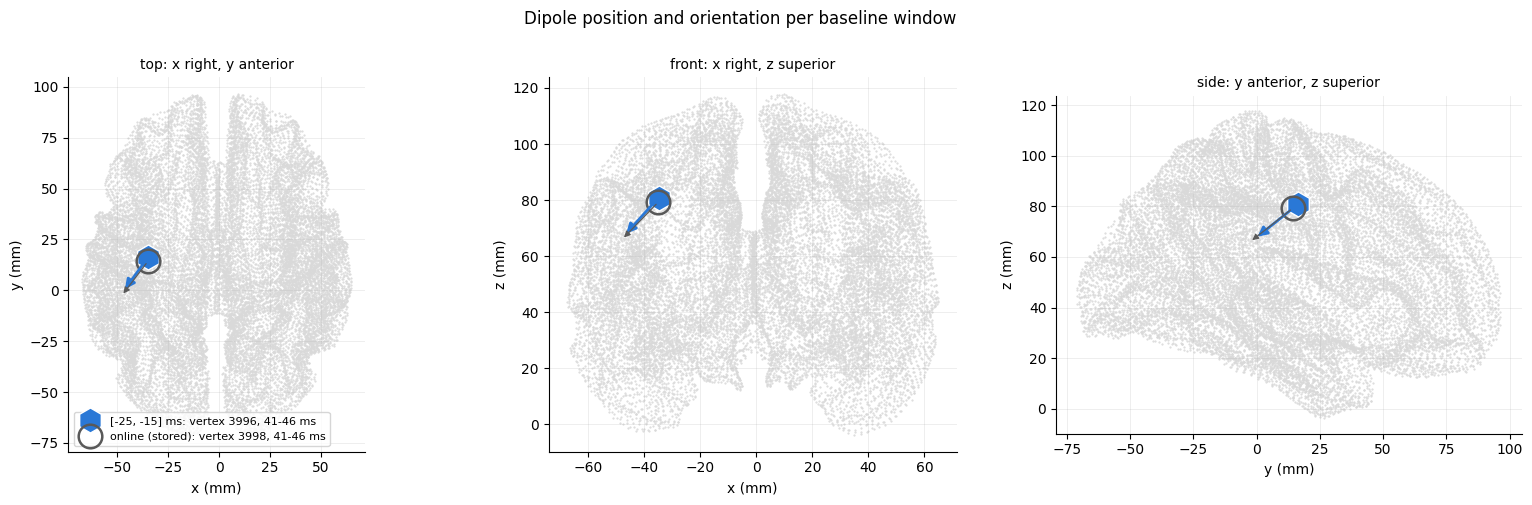

In [54]:
VIEWS = [(0, 1, "top: x right, y anterior"), (0, 2, "front: x right, z superior"), (1, 2, "side: y anterior, z superior")]


def save_fig(fig, name):
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def draw_dipoles(axes, names, arrow_mm=25):
    for ax, (h, v, title) in zip(axes, VIEWS):
        ax.scatter(SOURCE_RR[:, h], SOURCE_RR[:, v], s=0.3, color="0.85", rasterized=True)
        for name in names:
            d, st = DIPOLES[name], SOURCE_STYLE[name]
            p, o = d["position_mm"], d["orientation"] * arrow_mm
            ring = name == "online" and len(names) > 1        # online on top: a ring and a thin arrow
            ax.annotate("", xy=(p[h] + o[h], p[v] + o[v]), xytext=(p[h], p[v]),
                        arrowprops=dict(arrowstyle="-|>", color=st["color"], lw=0.9 if ring else 2,
                                        mutation_scale=9 if ring else 14))
            ax.plot(p[h], p[v], st["marker"], color=st["color"], mfc="none" if ring else st["mfc"],
                    mec=st["color"] if ring else "white", ms=17 if ring else MARKER_SIZE.get(name, 10),
                    mew=1.8 if ring else 1.0,
                    label=f"{LABEL[name]}: vertex {d['vertex']}, {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms")
        ax.set_xlabel(f"{'xyz'[h]} (mm)")
        ax.set_ylabel(f"{'xyz'[v]} (mm)")
        ax.set_title(title, fontsize=10)
        ax.set_aspect("equal")


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
draw_dipoles(axes, DRAW_ORDER)
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Dipole position and orientation per baseline window", y=1.0)
fig.tight_layout()
save_fig(fig, "dipoles_positions")
plt.show()

### 6.2 Time windows

Left: each source's fitted window within the [38, 50] ms search range. Right: the calibration evoked response
seen through each source's own dipole (free-orientation amplitude at its vertex, as `fit_trial()` computes it per
sample), with the fitted window drawn thick. The shaded band at the start is the tapered artifact window.

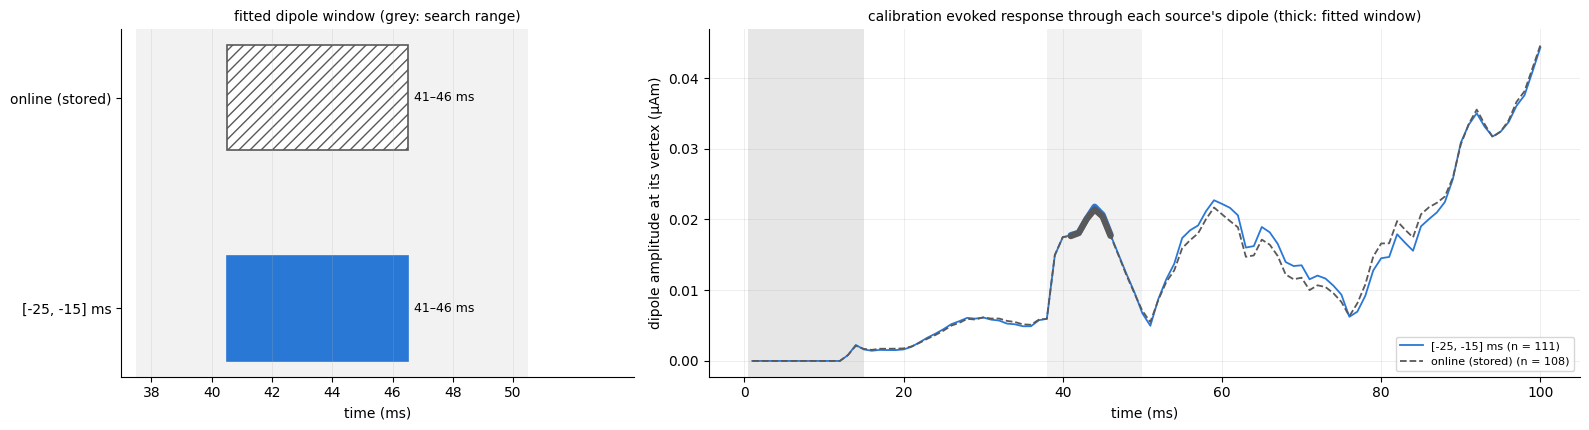

In [55]:
def dipole_waveform(src):
    # free-orientation dipole amplitude at the source's vertex, for every sample of the calibration evoked response
    evoked = CAL_EP[src].mean(axis=0)
    evoked = evoked - evoked.mean(axis=0)
    return np.linalg.norm(SRC[src]["pinv"] @ evoked, axis=0)


fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw=dict(width_ratios=[1, 1.7]))
ax = axes[0]
ax.axvspan(DIP_TMIN * 1e3 - 0.5, DIP_TMAX * 1e3 + 0.5, color="0.95", lw=0, zorder=0)
for i, src in enumerate(SOURCES[::-1]):
    d, st = DIPOLES[src], SOURCE_STYLE[src]
    w0, w1 = d["window_ms"]
    ax.barh(i, w1 - w0 + 1, left=w0 - 0.5, height=0.5, color=st["color"] if src != "online" else "white",
            edgecolor=st["color"], hatch="///" if src == "online" else None, lw=1.2)
    ax.text(w1 + 0.7, i, f"{w0:.0f}–{w1:.0f} ms", va="center", fontsize=9)
ax.set_yticks(range(len(SOURCES)))
ax.set_yticklabels([LABEL[s] for s in SOURCES[::-1]])
ax.set_xlim(DIP_TMIN * 1e3 - 1, DIP_TMAX * 1e3 + 4)
ax.set_xticks(np.arange(DIP_TMIN * 1e3, DIP_TMAX * 1e3 + 1, 2))
ax.set_xlabel("time (ms)")
ax.set_title("fitted dipole window (grey: search range)", fontsize=10)
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.axvspan(TIMES_MS[0] - 0.5, TAPER_END * 1e3, color="0.9", lw=0, zorder=0)
ax.axvspan(DIP_TMIN * 1e3, DIP_TMAX * 1e3, color="0.95", lw=0, zorder=0)
for src in DRAW_ORDER:
    st, wf = SOURCE_STYLE[src], dipole_waveform(src)
    s, e = DIPOLES[src]["index_range"]
    idx = np.arange(DIP_IDX.start + s, DIP_IDX.start + e)
    ax.plot(TIMES_MS, wf, color=st["color"], ls=st["ls"], lw=1.3, label=f"{LABEL[src]} (n = {len(CAL_EP[src])})")
    ax.plot(TIMES_MS[idx], wf[idx], color=st["color"], lw=4.5, solid_capstyle="round")
ax.set_xlabel("time (ms)")
ax.set_ylabel("dipole amplitude at its vertex (µAm)")
ax.set_title("calibration evoked response through each source's dipole (thick: fitted window)", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "dipoles_windows")
plt.show()

## 7 · Dipoles compared with the online dipole

### 7.1 Differences

For each candidate against the stored online dipole: distance between the vertices, angle between the
orientations, the fitted windows, the correlation of the two dipoles' scalp patterns (their leadfield
topographies; two vertices 20 mm apart can still project almost the same map), and the Spearman ρ of single-trial
amplitudes on the trials both keep, for the calibration and the open-loop trials. ρ is how much the ranking of
trials changes, which is what the normaliser's labels and PRIME's training follow. Saved as
`dipoles_vs_online.csv`.

In [56]:
def angle_deg(a, b):
    return float(np.degrees(np.arccos(np.clip(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)), -1, 1))))


def scalp_pattern(src):
    return SRC[src]["Lp"] @ DIPOLES[src]["orientation"]


def shared_rho(tab, tab_online, key):
    both = tab[tab.kept][[key, "amplitude"]].merge(tab_online[tab_online.kept][[key, "amplitude"]], on=key,
                                                   suffixes=("", "_online")).dropna()
    if len(both) < 4:
        return np.nan, len(both)
    return float(stats.spearmanr(both.amplitude, both.amplitude_online)[0]), len(both)


on = DIPOLES["online"]
rows = []
for src in CANDS:
    d = DIPOLES[src]
    (s, e), (so, eo) = d["index_range"], on["index_range"]
    rho_cal, n_cal = shared_rho(CAL_TAB[src].assign(kept=True), CAL_TAB["online"].assign(kept=True), "trial")
    rho_open, n_open = shared_rho(OPEN_TAB[src], OPEN_TAB["online"], "stem")
    rows.append({"candidate": LABEL[src], "vertex": d["vertex"], "online vertex": on["vertex"],
                 "distance (mm)": float(np.linalg.norm(d["position_mm"] - on["position_mm"])),
                 "orientation angle (°)": angle_deg(d["orientation"], on["orientation"]),
                 "window (ms)": f"{d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f}",
                 "online window (ms)": f"{on['window_ms'][0]:.0f}-{on['window_ms'][1]:.0f}",
                 "window start shift (ms)": d["window_ms"][0] - on["window_ms"][0],
                 "shared window samples": max(0, min(e, eo) - max(s, so)),
                 "scalp pattern r": float(np.corrcoef(scalp_pattern(src), scalp_pattern("online"))[0, 1]),
                 "amplitude ρ, calibration": rho_cal, "calibration trials (both keep)": n_cal,
                 "amplitude ρ, open-loop": rho_open, "open-loop trials (both keep)": n_open})
DIPOLE_VS_ONLINE = pd.DataFrame(rows).set_index("candidate")
display(DIPOLE_VS_ONLINE.round(3))
DIPOLE_VS_ONLINE.to_csv(OUT_DIR / "dipoles_vs_online.csv")

,vertex,online vertex,distance (mm),orientation angle (°),window (ms),online window (ms),window start shift (ms),shared window samples,scalp pattern r,"amplitude ρ, calibration",calibration trials (both keep),"amplitude ρ, open-loop",open-loop trials (both keep)
candidate,,,,,,,,,,,,,
"[-25, -15] ms",3996,3998,2.817,1.609,41-46,41-46,0.0,6,0.999,0.995,107,0.998,458


### 7.2 Bootstrap stability

Each source's dipole is refitted on `N_BOOT` resamples (with replacement) of its own surviving calibration
trials, with the online procedure: `dipoles_for_indices()` → `determine_optimal_index_range()` →
`determine_optimal_ori_and_pos()`. The spread shows how far a dipole moves through resampling alone. Each
candidate's distance to the online dipole is then placed among the online dipole's own resampling distances:
a candidate beyond most of them has moved further than resampling can explain.

`dipoles_for_indices()` recomputes the leadfield pseudo-inverses and scans the source space sample by sample,
about a second per fit. Here the pseudo-inverses are computed once and the scan covers all samples at once; the
best positions are then scored with the online arithmetic, so the same position wins. The refit on all trials is
checked against each source's dipole first. Saved as `dipole_bootstrap.csv` (one row per resample) and
`dipole_bootstrap_summary.csv`.

In [57]:
class DipoleScan:
    # dipoles_for_indices() of dipole_fitter.py, faster. The leadfield pseudo-inverses are computed once, and the R²
    # of every source position is computed for all samples at once through the projection identity
    # ||L pinv(L) y||² = (L'y)·(pinv(L) y). The positions within 1e-4 of the best are then scored with the online
    # arithmetic, so the chosen position is the one dipoles_for_indices() chooses.
    def __init__(self, forward):
        L = forward["sol"]["data"] - np.mean(forward["sol"]["data"], axis=0)    # average-reference leadfield
        self.n_pos = L.shape[1] // 3
        self.L3 = L.reshape(L.shape[0], self.n_pos, 3).transpose(1, 0, 2)       # (n_pos, n_ch, 3)
        self.pinv = np.linalg.pinv(self.L3)                                      # (n_pos, 3, n_ch)
        self.pinv2d = self.pinv.reshape(self.n_pos * 3, -1)
        self.Lt2d = np.ascontiguousarray(self.L3.transpose(0, 2, 1)).reshape(self.n_pos * 3, -1)
        self.rr = forward["source_rr"]

    def dipoles(self, evoked):
        data = evoked - np.mean(evoked, axis=0)
        n_t = data.shape[1]
        Q = (self.pinv2d @ data).reshape(self.n_pos, 3, n_t)
        approx = ((self.Lt2d @ data).reshape(self.n_pos, 3, n_t) * Q).sum(axis=1) / (data ** 2).sum(axis=0)
        out = []
        for index in range(n_t):
            y = data[:, index]
            near = np.flatnonzero(approx[:, index] >= approx[:, index].max() - 1e-4)
            q = self.pinv[near] @ y                                              # as dipoles_for_indices()
            ypred = np.einsum("nij,nj->ni", self.L3[near], q)
            r2 = np.einsum("ni,ni->n", ypred, ypred) / np.dot(y, y)
            k = int(np.argmax(r2))
            best, amplitude = int(near[k]), float(np.linalg.norm(q[k]))
            out.append({"amplitude": amplitude, "orientation": q[k] / amplitude, "position": self.rr[best],
                        "index": index, "position_index": best, "moment": q[k], "r2": float(r2[k]),
                        "data_predicted": ypred[k]})
        return out

    def fit(self, dipole_buffers, fitter):
        # DipoleFitter.calibrate() without the single-trial fits
        dipoles = self.dipoles(np.mean(dipole_buffers, axis=0))
        index_range, in_range = determine_optimal_index_range(
            dipoles, fitter._min_window_size, fitter._max_window_size, fitter._window_size_exponent)
        position_index, orientation = determine_optimal_ori_and_pos(in_range, fitter._forward)
        return {"position_index": position_index, "orientation": orientation, "index_range": index_range}


if N_BOOT > 0:
    SCAN = DipoleScan(SRC["online"]["fitter"]._forward)
    for src in SOURCES:
        info, ref = SCAN.fit(SRC[src]["dipole_buffers"], SRC[src]["fitter"]), SRC[src]["fitting_info"]
        same = (int(info["position_index"]) == int(ref["position_index"])
                and tuple(info["index_range"]) == tuple(ref["index_range"])
                and np.allclose(info["orientation"], ref["orientation"], atol=1e-8))
        print(f"{LABEL[src]:18s} refit on all its calibration trials reproduces its dipole: {same}")

    rng, rows, t0 = np.random.default_rng(BOOT_SEED), [], time.time()
    for src in SOURCES:
        db = SRC[src]["dipole_buffers"]
        for b in range(N_BOOT):
            info = SCAN.fit(db[rng.integers(0, len(db), len(db))], SRC[src]["fitter"])
            v, (s, e) = int(info["position_index"]), info["index_range"]
            rows.append({"source": LABEL[src], "resample": b, "vertex": v, "x (mm)": SOURCE_RR[v, 0],
                         "y (mm)": SOURCE_RR[v, 1], "z (mm)": SOURCE_RR[v, 2],
                         "orientation x": info["orientation"][0], "orientation y": info["orientation"][1],
                         "orientation z": info["orientation"][2],
                         "window start (ms)": DIP_TMIN * 1e3 + s, "window end (ms)": DIP_TMIN * 1e3 + e - 1})
    BOOT = pd.DataFrame(rows)
    BOOT.to_csv(OUT_DIR / "dipole_bootstrap.csv", index=False)
    print(f"{N_BOOT} resamples x {len(SOURCES)} sources in {time.time() - t0:.0f} s")

    def boot_distances(src, to_src=None):
        b = BOOT[BOOT.source == LABEL[src]]
        ref = DIPOLES[to_src or src]
        return np.linalg.norm(b[["x (mm)", "y (mm)", "z (mm)"]].to_numpy() - ref["position_mm"], axis=1)

    rows = []
    for src in SOURCES:
        b, d = BOOT[BOOT.source == LABEL[src]], DIPOLES[src]
        dist = boot_distances(src)
        ori = b[["orientation x", "orientation y", "orientation z"]].to_numpy()
        ang = [angle_deg(o, d["orientation"]) for o in ori]
        same_window = (b["window start (ms)"] == d["window_ms"][0]) & (b["window end (ms)"] == d["window_ms"][1])
        row = {"source": LABEL[src], "trials": len(SRC[src]["dipole_buffers"]),
               "same vertex (%)": 100 * float((b.vertex == d["vertex"]).mean()),
               "distance to own dipole: median (mm)": float(np.median(dist)),
               "distance to own dipole: 95th pct (mm)": float(np.percentile(dist, 95)),
               "orientation change: median (°)": float(np.median(ang)),
               "same window (%)": 100 * float(same_window.mean())}
        if src != "online":
            shift = float(np.linalg.norm(d["position_mm"] - DIPOLES["online"]["position_mm"]))
            row["distance to online (mm)"] = shift
            row["online resamples closer to online than this (%)"] = 100 * float(np.mean(boot_distances("online") < shift))
        rows.append(row)
    BOOT_SUMMARY = pd.DataFrame(rows).set_index("source")
    display(BOOT_SUMMARY.round(1))
    BOOT_SUMMARY.to_csv(OUT_DIR / "dipole_bootstrap_summary.csv")
else:
    print("N_BOOT = 0: bootstrap skipped")

online (stored)    refit on all its calibration trials reproduces its dipole: True
[-25, -15] ms      refit on all its calibration trials reproduces its dipole: True
200 resamples x 2 sources in 9 s


,trials,same vertex (%),distance to own dipole: median (mm),distance to own dipole: 95th pct (mm),orientation change: median (°),same window (%),distance to online (mm),online resamples closer to online than this (%)
source,,,,,,,,
online (stored),108,1.0,17.8,55.1,12.8,23.0,NaN,NaN
"[-25, -15] ms",111,0.5,20.0,55.0,12.5,25.5,2.8,4.5


Resampled dipole positions (small dots) around each source's dipole (large marker).

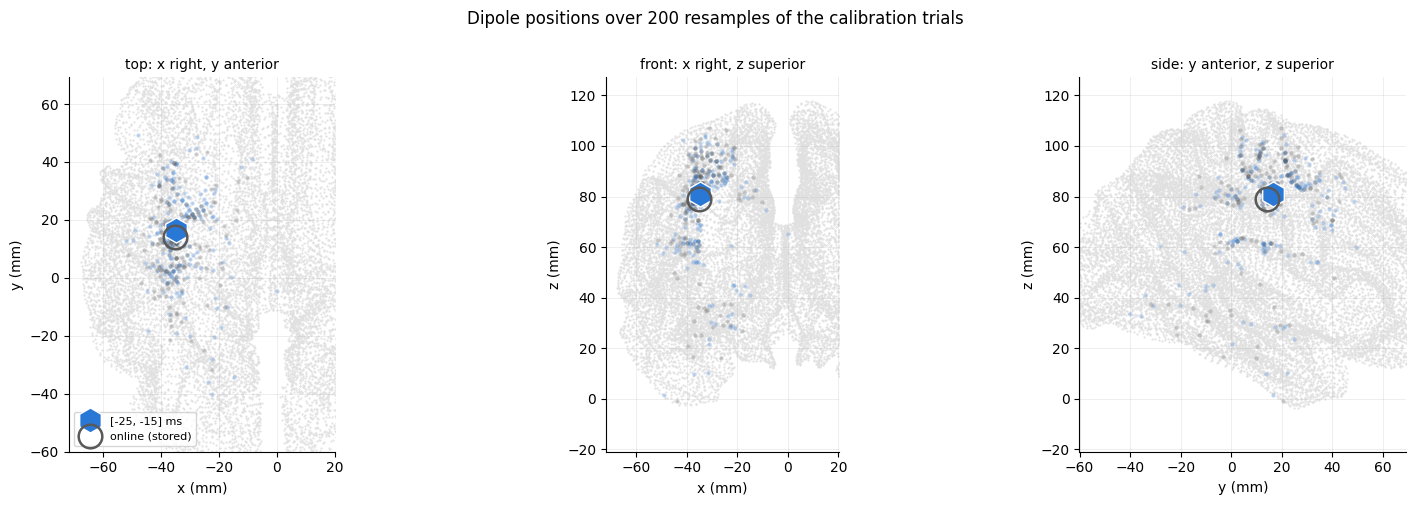

In [58]:
if N_BOOT > 0:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, (h, v, title) in zip(axes, VIEWS):
        ax.scatter(SOURCE_RR[:, h], SOURCE_RR[:, v], s=0.3, color="0.88", rasterized=True)
        for src in DRAW_ORDER:
            st, b, d = SOURCE_STYLE[src], BOOT[BOOT.source == LABEL[src]], DIPOLES[src]
            cols = ["x (mm)", "y (mm)", "z (mm)"]
            ax.scatter(b[cols[h]], b[cols[v]], s=10, color=st["color"], alpha=0.25, lw=0)
            ring = src == "online"
            ax.plot(d["position_mm"][h], d["position_mm"][v], st["marker"], color=st["color"],
                    mfc="none" if ring else st["mfc"], mec=st["color"] if ring else "white",
                    ms=17 if ring else MARKER_SIZE.get(src, 10), mew=1.8 if ring else 1.0, label=LABEL[src])
        ax.set_xlabel(f"{'xyz'[h]} (mm)")
        ax.set_ylabel(f"{'xyz'[v]} (mm)")
        ax.set_title(title, fontsize=10)
        ax.set_aspect("equal")
        pts = BOOT[["x (mm)", "y (mm)", "z (mm)"]].to_numpy()
        ax.set_xlim(pts[:, h].min() - 20, pts[:, h].max() + 20)
        ax.set_ylim(pts[:, v].min() - 20, pts[:, v].max() + 20)
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle(f"Dipole positions over {N_BOOT} resamples of the calibration trials", y=1.0)
    fig.tight_layout()
    save_fig(fig, "dipoles_bootstrap")
    plt.show()

## 8 · Sensor-space TEPs

The epochs are the [1, 100] ms output of each source's whole post chain, what the dipole fit sees: baseline →
artifact taper → bad-channel interpolation → average reference → ICA → baseline → SOUND → SSP-SIR → taper →
average reference. Each source averages its own trials that pass its gates, so the TEPs differ through the
baseline, through the filters fitted on the baselined data (SOUND, SSP-SIR) and through which trials survive.
Amplitudes are in the units of the acquisition stream (µV scale, uncalibrated). The first 15 ms are tapered
towards zero (dark band); the light band is the dipole search window.

Per trial set, four figures: butterflies (one panel per source, its own dipole window tinted); GMFA and Cz; the
left-M1 ROI (mean, then each channel; channels interpolated as bad channels are marked); topographies of the
mean over `TOPO_WINDOW` and over each source's own dipole window, on one colour scale per trial set (black rings:
ROI channels). The evoked responses are saved as `tep_evoked.npz`, the curves as `tep_curves.csv`.

In [59]:
ROI_IDX = [CH_NAMES.index(c) for c in ROI_CHANNELS]
CH_IDX = CH_NAMES.index(SINGLE_CHANNEL)
TOPO_IDX = slice(int(round((TOPO_WINDOW[0] - POST_TMIN) * PROC_SFREQ)),
                 int(round((TOPO_WINDOW[1] - POST_TMIN) * PROC_SFREQ)) + 1)
TOPO_INFO = SRC["online"]["pp"]._info_processed
BAD = {src: {str(c) for c in SRC[src]["bundle"]["bad_channels"]} for src in SOURCES}
EVOKED, CURVES = {}, []


def interpolated_note(channels):
    # which of these channels the sources interpolated as bad channels
    everywhere = [ch for ch in channels if all(ch in BAD[s] for s in SOURCES)]
    notes = [", ".join(everywhere) + " interpolated"] if everywhere else []
    for ch in channels:
        where = [LABEL[s] for s in SOURCES if ch in BAD[s]]
        if where and len(where) < len(SOURCES):
            notes.append(f"{ch} interpolated in {', '.join(where)}")
    return "; ".join(notes)


def channel_title(ch):
    where = [s for s in SOURCES if ch in BAD[s]]
    if not where:
        return ch
    if len(where) == len(SOURCES):
        return f"{ch} (interpolated)"
    return f"{ch} (interpolated in {', '.join(LABEL[s] for s in where)})"


def shade(ax):
    ax.axvspan(TIMES_MS[0] - 0.5, TAPER_END * 1e3, color="0.88", lw=0, zorder=0)    # tapered artifact window
    ax.axvspan(DIP_TMIN * 1e3, DIP_TMAX * 1e3, color="0.95", lw=0, zorder=0)        # dipole search window


def own_window(src):
    s, e = DIPOLES[src]["index_range"]
    return slice(DIP_IDX.start + s, DIP_IDX.start + e)


def tep_figures(key, title, epochs):
    srcs = [s for s in SOURCES if len(epochs[s])]
    ev = {s: epochs[s].mean(axis=0) for s in srcs}
    n = {s: len(epochs[s]) for s in srcs}
    EVOKED[key] = (ev, n)
    for s in srcs:
        CURVES.append(pd.DataFrame({"trial set": key, "source": LABEL[s], "trials": n[s], "time (ms)": TIMES_MS,
                                    "GMFA": ev[s].std(axis=0), "ROI mean": ev[s][ROI_IDX].mean(axis=0),
                                    **{ch: ev[s][CH_NAMES.index(ch)] for ch in ROI_CHANNELS + [SINGLE_CHANNEL]}}))
    draw = [s for s in DRAW_ORDER if s in ev]

    # butterflies
    fig, axes = plt.subplots(1, len(srcs), figsize=(3.4 * len(srcs), 3.6), sharey=True, squeeze=False)
    for ax, s in zip(axes[0], srcs):
        st = SOURCE_STYLE[s]
        shade(ax)
        w = own_window(s)
        ax.axvspan(TIMES_MS[w][0] - 0.5, TIMES_MS[w][-1] + 0.5, color=st["color"], alpha=0.18, lw=0, zorder=0)
        ax.plot(TIMES_MS, ev[s].T, color=st["color"], lw=0.6, alpha=0.8)
        ax.set_title(f"{LABEL[s]}\nn = {n[s]}", fontsize=10)
        ax.set_xlabel("time (ms)")
    axes[0][0].set_ylabel("amplitude (µV, uncalibrated)")
    fig.suptitle(f"{title}: all channels", y=1.03)
    fig.tight_layout()
    save_fig(fig, f"tep_{key}_butterfly")
    plt.show()

    # GMFA and the single channel
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
    for s in draw:
        st = SOURCE_STYLE[s]
        axes[0].plot(TIMES_MS, ev[s].std(axis=0), color=st["color"], ls=st["ls"], lw=1.8, label=f"{LABEL[s]} (n = {n[s]})")
        axes[1].plot(TIMES_MS, ev[s][CH_IDX], color=st["color"], ls=st["ls"], lw=1.8)
    axes[0].set(title="global mean field amplitude (GMFA)", ylabel="µV (uncalibrated)", xlabel="time (ms)")
    axes[1].set(title=channel_title(SINGLE_CHANNEL), ylabel="µV (uncalibrated)", xlabel="time (ms)")
    for ax in axes:
        shade(ax)
    axes[0].legend(fontsize=8)
    fig.suptitle(f"{title}: GMFA and {SINGLE_CHANNEL}", y=1.02)
    fig.tight_layout()
    save_fig(fig, f"tep_{key}_gmfa_{SINGLE_CHANNEL}")
    plt.show()

    # left-M1 ROI: mean, then each channel
    panels = [("ROI mean (" + ", ".join(ROI_CHANNELS) + ")", ROI_IDX)] + [(ch, [CH_NAMES.index(ch)]) for ch in ROI_CHANNELS]
    ncol = 4
    nrow = int(np.ceil((len(panels) + 1) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.3 * nrow), sharex=True, sharey=True, squeeze=False)
    for ax, (name, idx) in zip(axes.flat, panels):
        shade(ax)
        for s in draw:
            st = SOURCE_STYLE[s]
            ax.plot(TIMES_MS, ev[s][idx].mean(axis=0), color=st["color"], ls=st["ls"], lw=2.2 if len(idx) > 1 else 1.6)
        if len(idx) > 1:
            note = interpolated_note(ROI_CHANNELS)
            ax.set_title(f"{name}\n{note}" if note else name, fontsize=9)
        else:
            ax.set_title(channel_title(name), fontsize=10)
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    handles = [Line2D([], [], color=SOURCE_STYLE[s]["color"], ls=SOURCE_STYLE[s]["ls"], lw=2, label=f"{LABEL[s]} (n = {n[s]})")
               for s in srcs]
    axes.flat[len(panels)].legend(handles=handles, loc="center", fontsize=9, frameon=False)
    for ax in axes[-1]:
        ax.set_xlabel("time (ms)")
    for ax in axes[:, 0]:
        ax.set_ylabel("µV (uncalibrated)")
    fig.suptitle(f"{title}: left M1 ROI", y=1.01)
    fig.tight_layout()
    save_fig(fig, f"tep_{key}_roi")
    plt.show()

    # topographies: TOPO_WINDOW and each source's own dipole window, one colour scale
    rows_def = [(f"{TOPO_WINDOW[0] * 1e3:.0f}–{TOPO_WINDOW[1] * 1e3:.0f} ms", lambda s: TOPO_IDX),
                ("own dipole window", own_window)]
    maps = {(r, s): ev[s][:, f(s)].mean(axis=1) for r, (_, f) in enumerate(rows_def) for s in srcs}
    vmax = max(float(np.abs(m).max()) for m in maps.values())
    fig, axes = plt.subplots(2, len(srcs), figsize=(2.9 * len(srcs) + 1.2, 6.2), squeeze=False)
    mask = np.isin(CH_NAMES, ROI_CHANNELS)
    for r, (row_title, f) in enumerate(rows_def):
        for c, s in enumerate(srcs):
            ax = axes[r, c]
            im, _ = mne.viz.plot_topomap(maps[(r, s)], TOPO_INFO, axes=ax, show=False, vlim=(-vmax, vmax),
                                         cmap="RdBu_r", contours=6, mask=mask,
                                         mask_params=dict(marker="o", markerfacecolor="none", markeredgecolor="black",
                                                          markeredgewidth=1.0, markersize=5))
            w = TIMES_MS[f(s)]
            ax.set_title(f"{LABEL[s]}\n{w[0]:.0f}–{w[-1]:.0f} ms" if r else f"{LABEL[s]}\n{row_title}", fontsize=9)
    fig.colorbar(im, ax=axes, shrink=0.6, label="µV (uncalibrated)")
    fig.suptitle(f"{title}: topography, top {rows_def[0][0]}, bottom each source's dipole window", y=1.0)
    save_fig(fig, f"tep_{key}_topo")
    plt.show()

### 8.1 Calibration block

Each source's own surviving calibration trials (the trials its dipole was fitted on).

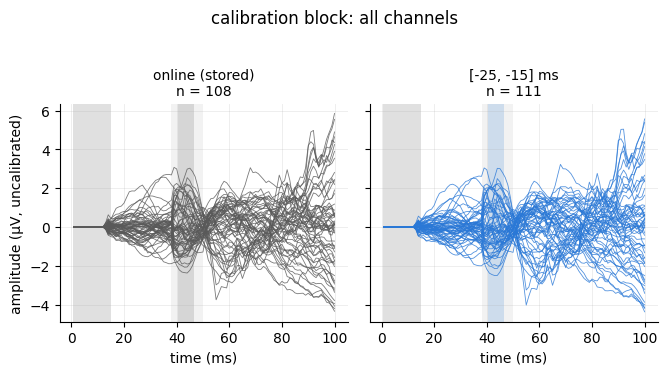

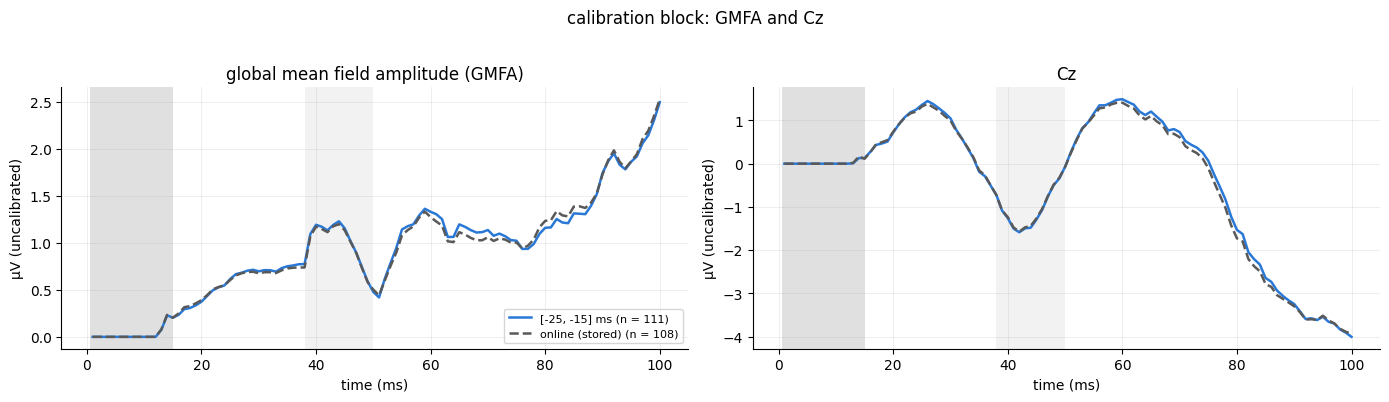

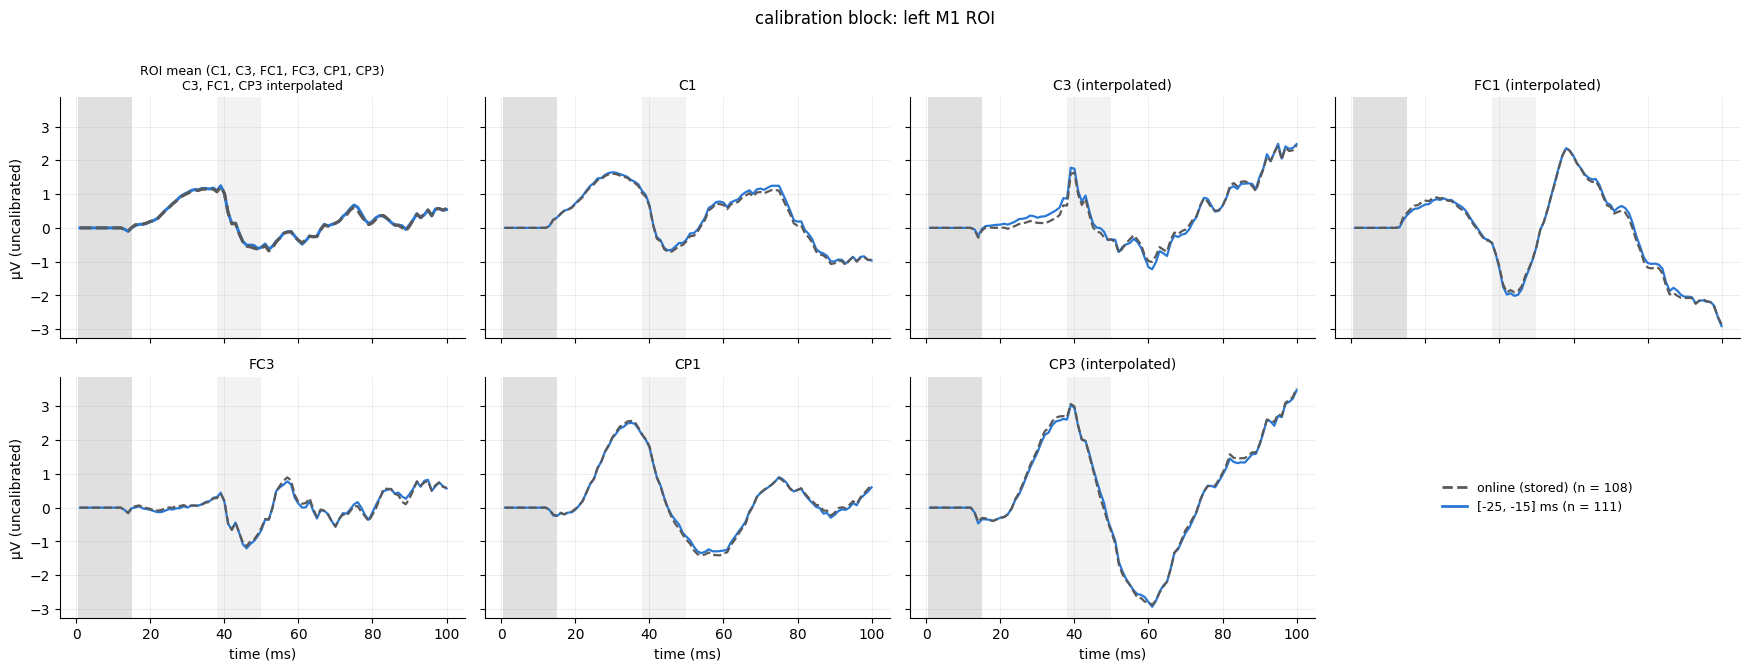

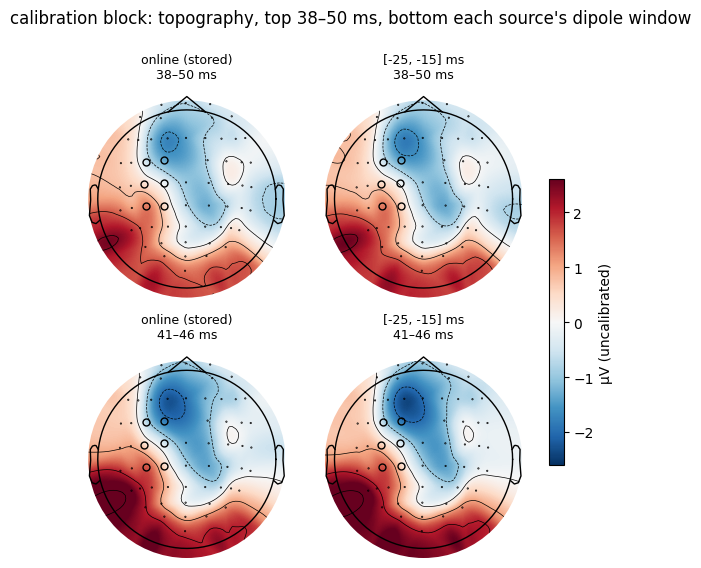

In [60]:
tep_figures("calibration", "calibration block", CAL_EP)

### 8.2 Baseline and evaluation blocks

The open-loop trials of the baseline block and the four evaluation blocks together, each source keeping the trials
its gates pass. First the trials per block and the rejection reasons.

trials passing the gates, per block


,online (stored),"[-25, -15] ms"
block,,
baseline,95 / 100,95 / 100
t0,92 / 100,92 / 100
t15,90 / 100,90 / 100
t30,96 / 100,94 / 100
t60,90 / 100,92 / 100


reject reason


,online (stored),"[-25, -15] ms"
reject_reason,,
kept,463,463
ocular,27,26
local_mad,8,9
global_mad,2,2


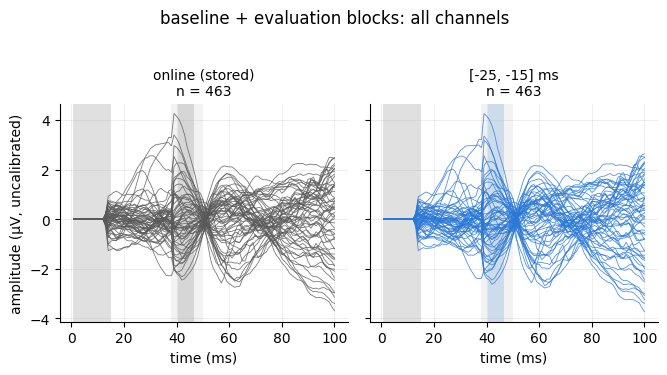

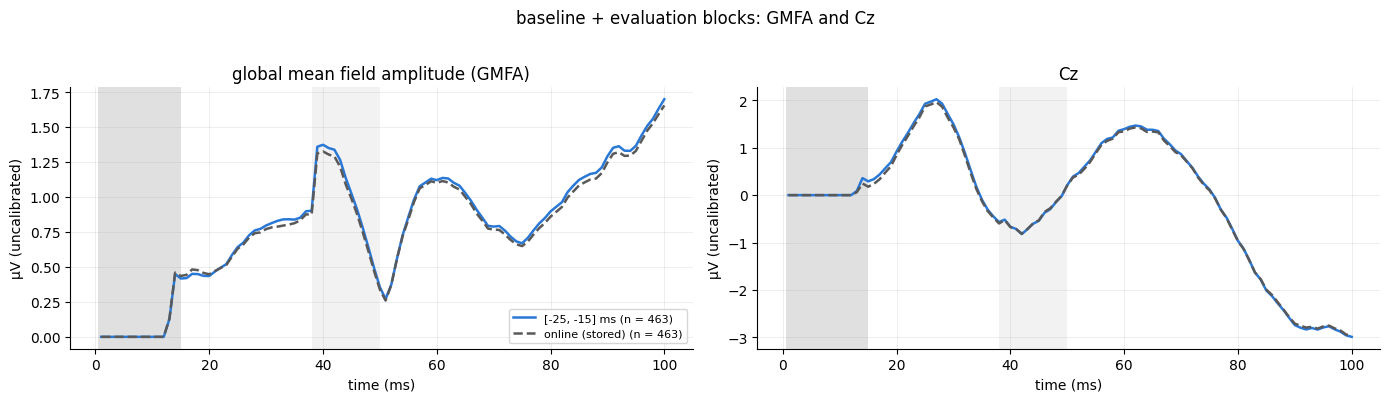

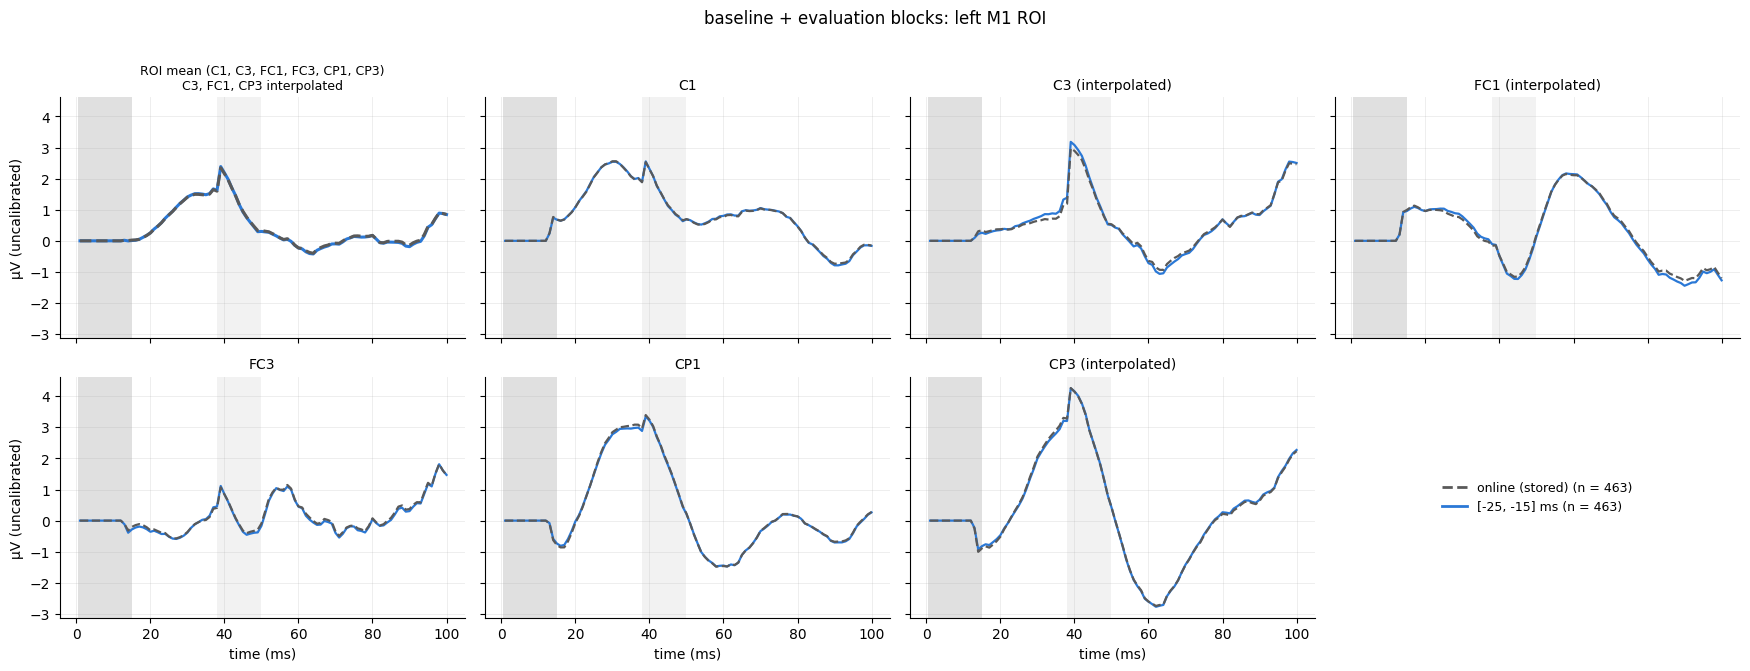

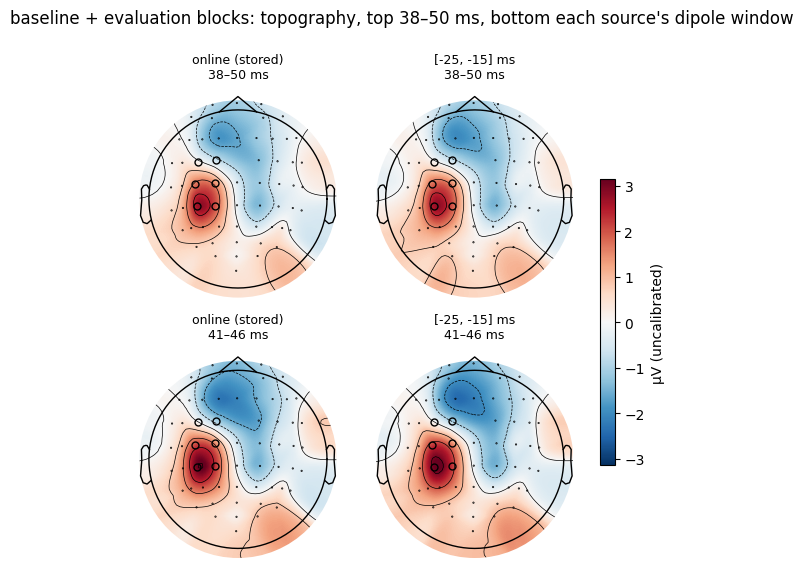

In [61]:
kept = pd.DataFrame({LABEL[s]: OPEN_TAB[s].groupby("block", sort=False).kept.agg(lambda k: f"{int(k.sum())} / {len(k)}")
                     for s in SOURCES})
print("trials passing the gates, per block")
display(kept)
reasons = pd.DataFrame({LABEL[s]: OPEN_TAB[s].reject_reason.fillna("kept").value_counts() for s in SOURCES})
print("reject reason")
display(reasons.fillna(0).astype(int))
tep_figures("open_loop", "baseline + evaluation blocks", OPEN_EP)

### 8.3 Save the TEPs

In [62]:
arrays = {"times_ms": TIMES_MS, "ch_names": np.array(CH_NAMES)}
for key, (ev, n) in EVOKED.items():
    for s in ev:
        arrays[f"{key}__{s}"] = ev[s]
        arrays[f"{key}__{s}__n"] = np.array(n[s])
np.savez(OUT_DIR / "tep_evoked.npz", **arrays)
pd.concat(CURVES, ignore_index=True).to_csv(OUT_DIR / "tep_curves.csv", index=False)
print(f"tep_evoked.npz: keys '<trial set>__<source>' ({', '.join(EVOKED)} x {', '.join(SOURCES)}), channels x time")
print(f"tep_curves.csv: GMFA, ROI mean, {', '.join(ROI_CHANNELS + [SINGLE_CHANNEL])} per trial set and source")

tep_evoked.npz: keys '<trial set>__<source>' (calibration, open_loop x online, -25_-15), channels x time
tep_curves.csv: GMFA, ROI mean, C1, C3, FC1, FC3, CP1, CP3, Cz per trial set and source


## Summary

In [63]:
print(f"{SUBJECT_ID}, {len(CAL)} calibration trials, {len(OPEN)} open-loop trials\n")
for src in SOURCES:
    b, d = SRC[src]["bundle"], DIPOLES[src]
    line = (f"{LABEL[src]:18s} kept {len(b['trials_kept']):3d} (ocular {len(b['trials_dropped']['ocular'])}, "
            f"pre MAD {len(b['trials_dropped']['qc'])}, post MAD {len(b['trials_dropped']['post'])}); "
            f"dipole {d['vertex']}, {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms, R² {d['r2']:.2f}")
    if src != "online":
        r = DIPOLE_VS_ONLINE.loc[LABEL[src]]
        line += (f"; vs online {r['distance (mm)']:.1f} mm, {r['orientation angle (°)']:.1f}°, "
                 f"scalp r {r['scalp pattern r']:.3f}, amplitude ρ {r['amplitude ρ, calibration']:.2f} / "
                 f"{r['amplitude ρ, open-loop']:.2f}")
        if N_BOOT > 0:
            line += (f"; shift larger than {BOOT_SUMMARY.loc[LABEL[src], 'online resamples closer to online than this (%)']:.1f}% "
                     "of the online dipole's resampling shifts")
    line += f"; open-loop {int(OPEN_TAB[src].kept.sum())}/{len(OPEN_TAB[src])} kept"
    print(line)
print(f"\ntables and figures in {OUT_DIR}")
for p in sorted(OUT_DIR.glob("*.*")):
    print(f"  {p.name}")

pilot003, 125 calibration trials, 500 open-loop trials

online (stored)    kept 108 (ocular 8, pre MAD 3, post MAD 6); dipole 3998, 41-46 ms, R² 0.82; open-loop 463/500 kept
[-25, -15] ms      kept 111 (ocular 6, pre MAD 3, post MAD 5); dipole 3996, 41-46 ms, R² 0.81; vs online 2.8 mm, 1.6°, scalp r 0.999, amplitude ρ 1.00 / 1.00; shift larger than 4.5% of the online dipole's resampling shifts; open-loop 463/500 kept

tables and figures in D:\Linus\Loop\offline_baseline\sub-pilot003\baseline_candidates
  amplitudes_calibration.csv
  amplitudes_open_loop.csv
  calibration_kept_shared.csv
  calibration_outcomes.csv
  calibration_trials.csv
  dipole_bootstrap.csv
  dipole_bootstrap_summary.csv
  dipoles.csv
  dipoles_vs_online.csv
  tep_curves.csv
  tep_evoked.npz
